# Task 1 - Exploratory Data Analysis on Retail Sales Data

**Internship:** Oasis Infobyte &nbsp;|&nbsp; **Track:** Data Analytics &nbsp;|&nbsp; **Level:** 1
**Author:** Vivek Shukla ([GitHub](https://github.com/VivekShukla04))
**Repository:** [VivekShukla04/OIBSIP](https://github.com/VivekShukla04/OIBSIP)

---

## 1. Objective

Perform a thorough **Exploratory Data Analysis (EDA)** on a retail sales transaction
dataset in order to:

1. Understand the structure, quality and basic statistics of the data.
2. Understand how **revenue and profit behave over time**.
3. Understand **which products and categories** drive sales and which destroy value.
4. Understand **customer behaviour** (segments, markets, repeat purchasing).
5. Quantify relationships between numeric variables.
6. Convert the findings into **actionable, data-backed business recommendations**.

## 2. Dataset Information

| Item | Value |
|---|---|
| Dataset name | Global Super Store Orders (public sample) |
| Source repository | `plotly/datasets` (openly published sample data repository) |
| Source URL | https://raw.githubusercontent.com/plotly/datasets/master/global_super_store_orders.tsv |
| Repository URL | https://github.com/plotly/datasets |
| Original dataset | *Global Superstore Orders* (5,129 order lines, widely used public retail dataset) |
| File used here | `data/global_super_store_orders.tsv` (the **public 1,000-line sample** of the same dataset) |
| Format | Tab-separated values (`.tsv`) |
| Grain | One row = one **order line item** (a product inside an order) |
| Period covered | 2011-01-01 to 2014-12-30 |
| Licence / usage | Publicly published sample data, used here for educational data-analytics work |

### Important notes about the data (nothing is invented)

* This is a **real, published dataset**. No field has been created, simulated or estimated.
* The file stores numbers using the **European decimal comma** (`45,06`, `0,2`, `-3.701,89`),
  so `Sales`, `Discount`, `Profit` and `Shipping Cost` arrive as *text* and **must be converted**
  to numeric before any statistics or charts are correct.
* The dataset contains **no `Age` and no `Gender` column**. Because fabricating demographic
  fields is not acceptable, the customer-demographics section uses the *customer attributes that
  genuinely exist* in the file: `Segment` (Consumer / Corporate / Home Office), `Market`,
  `Region`, `City`, `Country` and `Ship Mode`. This limitation is restated in the conclusions.

## 3. Imports and Project Configuration

All paths are **relative to the project folder** (resolved programmatically), so the notebook runs
identically on any machine, from any working directory, with no machine-specific paths.

In [1]:
# --- Standard library -------------------------------------------------------
import warnings
from pathlib import Path

# --- Third-party libraries --------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Jupyter / IPython display options
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

%matplotlib inline

In [2]:
# --- Resolve the project folder without hard-coding any machine-specific path ---
PROJECT_NAME = "DataAnalytics-L1-EDARetailSales"


def find_project_dir(name: str) -> Path:
    # Walk up from the current working directory until the project folder is found.
    # This makes the notebook work whether it is launched from the project folder,
    # from the repository root, or from anywhere below the user's home directory.
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / name
        if candidate.is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError(
        f"Could not locate project folder '{name}' starting from {Path.cwd()}"
    )


PROJECT_DIR = find_project_dir(PROJECT_NAME)
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_FILE = DATA_DIR / "global_super_store_orders.tsv"

assert DATA_FILE.exists(), f"Dataset not found at {DATA_FILE}"

print("Project folder :", PROJECT_NAME, "(resolved relative to the current working directory)")
print("Dataset file   :", DATA_FILE.relative_to(PROJECT_DIR))
print("Output folder  :", OUTPUT_DIR.relative_to(PROJECT_DIR))

Project folder : DataAnalytics-L1-EDARetailSales (resolved relative to the current working directory)
Dataset file   : data/global_super_store_orders.tsv
Output folder  : outputs


In [3]:
# --- Consistent, professional visual style for every chart in the notebook ---
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = "Set2"
plt.rcParams.update({
    "figure.figsize": (11, 5.5),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.autolayout": False,
})

print("Visual style configured.")

Visual style configured.


## 4. Data Loading

The file is read as **tab-separated values**. The first column of the file is an unnamed
spreadsheet index, so it is dropped immediately.

In [4]:
df_raw = pd.read_csv(DATA_FILE, sep="\t", encoding="utf-8")
df_raw = df_raw.drop(columns=["Unnamed: 0"])

print("Raw shape :", df_raw.shape)
df_raw.head(5)

Raw shape : (1000, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Country,Postal Code,Market,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,29165,IN-2014-24531,8/15/14,8/19/14,Standard Class,AS-10285,Alejandro Savely,Corporate,Guangzhou,Guangdong,China,NaN,APAC,North Asia,OFF-SU-10001343,Office Supplies,Supplies,"Elite Scissors, High Speed","45,06",2,0,"5,4","3,53",Medium
1,39615,CA-2014-130904,4/12/14,4/17/14,Standard Class,HM-14980,Henry MacAllister,Consumer,Burlington,North Carolina,United States,"27,217.00",US,South,OFF-AR-10000127,Office Supplies,Art,Newell 321,"20,992",8,"0,2","2,3616","2,28",Medium
2,39158,CA-2012-142993,10/12/12,10/17/12,Standard Class,KA-16525,Kelly Andreada,Consumer,Seattle,Washington,United States,"98,103.00",US,West,TEC-AC-10003038,Technology,Accessories,Kingston Digital DataTraveler 16GB USB 2.0,"17,9",2,0,"3,401","1,91",Medium
3,2193,MX-2013-169502,6/13/13,6/15/13,Second Class,AJ-10960,Astrea Jones,Consumer,Santo Domingo,Santo Domingo,Dominican Republic,NaN,LATAM,Caribbean,TEC-AC-10001341,Technology,Accessories,"Enermax Memory Card, USB","183,36",3,"0,2","22,92","25,54",Critical
4,23217,IN-2014-50627,9/14/14,9/18/14,Standard Class,LW-16825,Laurel Workman,Corporate,Jinhua,Zhejiang,China,NaN,APAC,North Asia,OFF-EN-10001977,Office Supplies,Envelopes,"Cameo Business Envelopes, Recycled","31,5",2,0,"6,9","1,14",Medium


## 5. Initial Data Inspection

### 5.1 Dataset shape and column names

In [5]:
print(f"Rows    : {df_raw.shape[0]:,}")
print(f"Columns : {df_raw.shape[1]}")
print("\nColumn names:")
for i, col in enumerate(df_raw.columns, start=1):
    print(f"  {i:>2}. {col}")

Rows    : 1,000
Columns : 24

Column names:
   1. Row ID
   2. Order ID
   3. Order Date
   4. Ship Date
   5. Ship Mode
   6. Customer ID
   7. Customer Name
   8. Segment
   9. City
  10. State
  11. Country
  12. Postal Code
  13. Market
  14. Region
  15. Product ID
  16. Category
  17. Sub-Category
  18. Product Name
  19. Sales
  20. Quantity
  21. Discount
  22. Profit
  23. Shipping Cost
  24. Order Priority


### 5.2 Data types

Notice that the four money/percentage columns are loaded as **object (text)** because the file
uses decimal commas. This is the single most important data-quality issue in this dataset.

In [6]:
print("dtypes of the raw file:")
print(df_raw.dtypes.to_string())

dtypes of the raw file:
Row ID              int64
Order ID              str
Order Date            str
Ship Date             str
Ship Mode             str
Customer ID           str
Customer Name         str
Segment               str
City                  str
State                 str
Country               str
Postal Code       float64
Market                str
Region                str
Product ID            str
Category              str
Sub-Category          str
Product Name          str
Sales                 str
Quantity            int64
Discount              str
Profit                str
Shipping Cost         str
Order Priority        str


### 5.3 Missing values

Columns containing missing values:
             missing_count  missing_pct
Postal Code            804        80.40


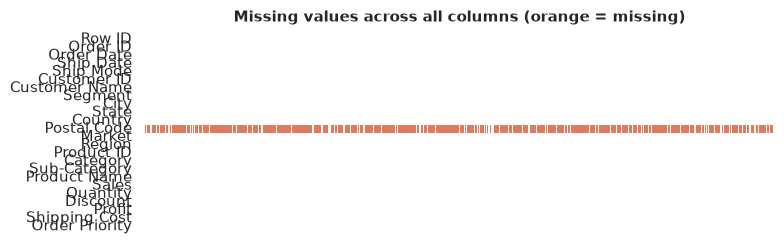

In [7]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().sum() / len(df_raw) * 100).round(2),
})
missing = missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)

print("Columns containing missing values:")
print(missing.to_string() if not missing.empty else "None")

# Quick visual of missing values
plt.figure(figsize=(8, 2.6))
sns.heatmap(df_raw.isna().T, cmap=["#ffffff", "#e07a5f"], cbar=False, yticklabels=True)
plt.title("Missing values across all columns (orange = missing)", fontsize=11, pad=10)
plt.xlabel("")
plt.xticks([])
plt.grid(False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_missing_values_overview.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation.** Only `Postal Code` contains missing values (804 of 1,000 rows). This is expected:
the Global Superstore sells to many countries whose address format does not use a numeric postal
code, so the field is blank for non-US-style addresses. No other column has a missing value, so no
imputation is required anywhere in this dataset — inventing values would only add noise.

### 5.4 Duplicate rows

In [8]:
duplicate_rows = df_raw.duplicated().sum()
duplicate_order_ids = df_raw["Order ID"].duplicated().sum()

print(f"Exact duplicate rows          : {duplicate_rows}")
print(f"Repeated 'Order ID' values    : {duplicate_order_ids}")
print(
    "Note: a repeated Order ID is NOT a duplicate — one order legitimately contains\n"
    "      many different products. Duplicates are therefore tested on full rows."
)

Exact duplicate rows          : 0
Repeated 'Order ID' values    : 21
Note: a repeated Order ID is NOT a duplicate — one order legitimately contains
      many different products. Duplicates are therefore tested on full rows.


## 6. Data Cleaning and Feature Engineering

Only the issues that are genuinely present are fixed:

1. **Decimal-comma to numeric conversion** for `Sales`, `Discount`, `Profit`, `Shipping Cost`.
2. **Date parsing** for `Order Date` and `Ship Date` (format `MM/DD/YY`).
3. **Derived analytical features**: delivery time, year, month, quarter, unit price,
   shipping cost as a share of sales, and a profit flag.

Nothing is dropped and no value is imputed, because the raw data has no missing business values.

In [9]:
df = df_raw.copy()

# --- 1. Numeric columns that use the European decimal comma ---------------------
NUMERIC_TEXT_COLUMNS = ["Sales", "Discount", "Profit", "Shipping Cost"]

for col in NUMERIC_TEXT_COLUMNS:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.strip().str.replace(",", ".", regex=False),
        errors="coerce",
    )

# --- 2. Dates ------------------------------------------------------------------
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%y", errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%y", errors="coerce")

# --- 3. Derived features --------------------------------------------------------
df["Delivery Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Year"] = df["Order Date"].dt.year
df["Quarter"] = df["Order Date"].dt.to_period("Q")
df["Month"] = df["Order Date"].dt.to_period("M")
df["Unit Price"] = (df["Sales"] / df["Quantity"]).round(4)
df["Shipping Cost Pct"] = (df["Shipping Cost"] / df["Sales"] * 100).round(2)
df["Is Loss Making"] = np.where(df["Profit"] < 0, "Loss", "Profit")

print("Cleaning complete. Any value that failed conversion is reported below.")
print("Unparsed dates   :", int(df["Order Date"].isna().sum() + df["Ship Date"].isna().sum()))
print("Unparsed numerics:", {c: int(df[c].isna().sum()) for c in NUMERIC_TEXT_COLUMNS})
print("Negative delivery days:", int((df["Delivery Days"] < 0).sum()))

Cleaning complete. Any value that failed conversion is reported below.
Unparsed dates   : 0
Unparsed numerics: {'Sales': 0, 'Discount': 0, 'Profit': 0, 'Shipping Cost': 0}
Negative delivery days: 0


In [10]:
print("dtypes after cleaning:")
print(df.dtypes.to_string())

dtypes after cleaning:
Row ID                        int64
Order ID                        str
Order Date           datetime64[us]
Ship Date            datetime64[us]
Ship Mode                       str
Customer ID                     str
Customer Name                   str
Segment                         str
City                            str
State                           str
Country                         str
Postal Code                 float64
Market                          str
Region                          str
Product ID                      str
Category                        str
Sub-Category                    str
Product Name                    str
Sales                       Float64
Quantity                      int64
Discount                    Float64
Profit                      Float64
Shipping Cost               Float64
Order Priority                  str
Delivery Days                 int64
Year                          int32
Quarter               period[Q-DEC]
Month

In [11]:
df.head(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Country,Postal Code,Market,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority,Delivery Days,Year,Quarter,Month,Unit Price,Shipping Cost Pct,Is Loss Making
0,29165,IN-2014-24531,2014-08-15,2014-08-19,Standard Class,AS-10285,Alejandro Savely,Corporate,Guangzhou,Guangdong,China,NaN,APAC,North Asia,OFF-SU-10001343,Office Supplies,Supplies,"Elite Scissors, High Speed",45.06,2,0.00,5.40,3.53,Medium,4,2014,2014Q3,2014-08,22.53,7.83,Profit
1,39615,CA-2014-130904,2014-04-12,2014-04-17,Standard Class,HM-14980,Henry MacAllister,Consumer,Burlington,North Carolina,United States,"27,217.00",US,South,OFF-AR-10000127,Office Supplies,Art,Newell 321,20.99,8,0.20,2.36,2.28,Medium,5,2014,2014Q2,2014-04,2.62,10.86,Profit
2,39158,CA-2012-142993,2012-10-12,2012-10-17,Standard Class,KA-16525,Kelly Andreada,Consumer,Seattle,Washington,United States,"98,103.00",US,West,TEC-AC-10003038,Technology,Accessories,Kingston Digital DataTraveler 16GB USB 2.0,17.90,2,0.00,3.40,1.91,Medium,5,2012,2012Q4,2012-10,8.95,10.67,Profit
3,2193,MX-2013-169502,2013-06-13,2013-06-15,Second Class,AJ-10960,Astrea Jones,Consumer,Santo Domingo,Santo Domingo,Dominican Republic,NaN,LATAM,Caribbean,TEC-AC-10001341,Technology,Accessories,"Enermax Memory Card, USB",183.36,3,0.20,22.92,25.54,Critical,2,2013,2013Q2,2013-06,61.12,13.93,Profit
4,23217,IN-2014-50627,2014-09-14,2014-09-18,Standard Class,LW-16825,Laurel Workman,Corporate,Jinhua,Zhejiang,China,NaN,APAC,North Asia,OFF-EN-10001977,Office Supplies,Envelopes,"Cameo Business Envelopes, Recycled",31.50,2,0.00,6.90,1.14,Medium,4,2014,2014Q3,2014-09,15.75,3.62,Profit


## 7. Descriptive Statistics

### 7.1 Central tendency and dispersion for the key numeric columns

In [12]:
numeric_cols = ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost", "Delivery Days", "Unit Price"]

summary = pd.DataFrame({
    "mean":     df[numeric_cols].mean(),
    "median":   df[numeric_cols].median(),
    "mode":     df[numeric_cols].mode().iloc[0],
    "std":      df[numeric_cols].std(),
    "min":      df[numeric_cols].min(),
    "max":      df[numeric_cols].max(),
    "skew":     df[numeric_cols].skew(),
})
summary.round(2)

,mean,median,mode,std,min,max,skew
Sales,243.96,84.19,12.96,483.57,1.41,"4,544.10",4.69
Quantity,3.39,3.00,2.00,2.17,1.00,14.00,1.36
Discount,0.14,0.00,0.00,0.21,0.00,0.80,1.36
Profit,28.01,9.03,0.00,201.81,"-3,701.89","1,868.13",-5.07
Shipping Cost,26.92,7.77,0.87,61.72,0.05,658.69,5.54
Delivery Days,3.91,4.00,4.00,1.76,0.00,7.00,-0.41
Unit Price,72.10,28.53,5.18,111.53,0.85,"1,088.79",3.19


**What this shows.** `Sales` has a mean of about 244 but a median of only 84 - a very large gap.
The distribution is strongly **right-skewed** (skew = 4.69): a few very large orders pull the
average far above the typical order. The same pattern holds for `Profit` (mean 28.01, median
9.03) and `Shipping Cost` (mean 26.92, median 7.77).

**Why it matters.** Reporting only the average would badly misrepresent this business. The mean
order line is worth almost **3x** the median one, so revenue planning, staffing and inventory
decisions must be based on the median and on percentiles, not on the mean.

### 7.2 Distribution of Sales, Profit and Discount

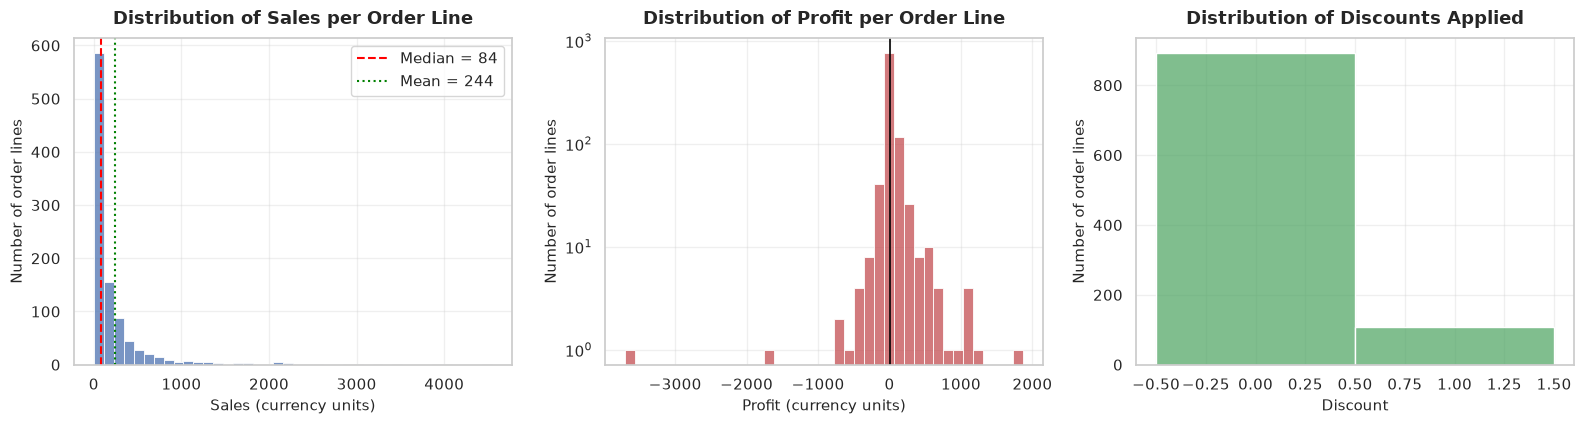

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

sns.histplot(df["Sales"], bins=40, color="#4c72b0", ax=axes[0])
axes[0].set_title("Distribution of Sales per Order Line", pad=10)
axes[0].set_xlabel("Sales (currency units)")
axes[0].set_ylabel("Number of order lines")
axes[0].axvline(df["Sales"].median(), color="red", linestyle="--", label=f"Median = {df['Sales'].median():,.0f}")
axes[0].axvline(df["Sales"].mean(), color="green", linestyle=":", label=f"Mean = {df['Sales'].mean():,.0f}")
axes[0].legend(frameon=True)

sns.histplot(df["Profit"], bins=40, color="#c44e52", ax=axes[1])
axes[1].set_title("Distribution of Profit per Order Line", pad=10)
axes[1].set_xlabel("Profit (currency units)")
axes[1].set_ylabel("Number of order lines")
axes[1].axvline(0, color="black", linewidth=1.2)
axes[1].set_yscale("log")

sns.histplot(df["Discount"], bins=25, color="#55a868", discrete=True, ax=axes[2])
axes[2].set_title("Distribution of Discounts Applied", pad=10)
axes[2].set_xlabel("Discount")
axes[2].set_ylabel("Number of order lines")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_distributions_sales_profit_discount.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** The Sales histogram is heavily concentrated below 100 with a long tail
reaching 4,544. The Profit histogram is plotted on a log scale because it spans losses (down to
-3,702) and gains (up to 1,868) — the log scale makes the small number of large negative
transactions visible, which a linear axis would hide.

**What pattern is visible.** Roughly one quarter of order lines are sold at a **loss**.
The discount histogram shows a distinctive **U-shaped** pattern: 56.4% of lines carry no
discount at all, but 209 lines (20.9%) carry a discount above 30%.

**Why it matters.** The loss-making tail and the deep-discount spike are the two most
commercially important facts in this dataset, and both are invisible in a simple summary table.

### 7.3 Most frequent (modal) values of the categorical columns

In [14]:
for col in ["Ship Mode", "Segment", "Category", "Market", "Order Priority", "Country"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().head(6).to_string())


--- Ship Mode ---
Ship Mode
Standard Class    585
Second Class      197
First Class       162
Same Day           56

--- Segment ---
Segment
Consumer       536
Corporate      273
Home Office    191

--- Category ---
Category
Office Supplies    620
Furniture          194
Technology         186

--- Market ---
Market
APAC      227
EU        202
US        196
LATAM     192
EMEA       89
Africa     88

--- Order Priority ---
Order Priority
Medium      598
High        287
Critical     83
Low          32

--- Country ---
Country
United States    196
France            61
Australia         60
China             45
Germany           41
Mexico            39


## 8. Time-Series Analysis

### 8.1 Yearly revenue and profit

In [15]:
yearly = df.groupby("Year").agg(
    Order_Lines=("Order ID", "size"),
    Orders=("Order ID", "nunique"),
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Discount=("Discount", "mean"),
).reset_index()

yearly["Margin %"] = (yearly["Profit"] / yearly["Revenue"] * 100).round(2)
yearly["Revenue"] = yearly["Revenue"].round(2)
yearly["Profit"] = yearly["Profit"].round(2)
yearly["Discount"] = (yearly["Discount"] * 100).round(2)
yearly.to_csv(OUTPUT_DIR / "yearly_summary.csv", index=False)

print(yearly.to_string(index=False))

 Year  Order_Lines  Orders   Revenue    Profit  Discount  Margin %
 2011          176     175 58,763.31  4,823.78     12.84      8.21
 2012          226     218 41,834.30  5,973.87     13.80     14.28
 2013          272     265 70,490.24 11,375.73     14.97     16.14
 2014          326     321 72,872.22  5,835.85     15.03      8.01


**What this shows.** Order lines grow every year - 176 (2011) to 326 (2014), with distinct orders
rising from 175 to 321 - and revenue ends at its highest point in 2014 (72,872). But **profit
does not follow revenue**: 2013 is the most profitable year (11,376 profit) while 2014's margin
collapses from 16.14% to **8.01%**, the weakest since 2011.

**What pattern is visible.** *Profit per order line* falls from 41.82 in 2013 to 17.90 in 2014
(**-57.2%**), and revenue per order line also slips from 259.16 to 223.53 (-13.8%) - so 2014 adds
volume while each line is worth less and earns far less.

**The important nuance:** this collapse is **not** explained by deeper average discounting. The
mean discount is essentially flat between the two years (14.97% -> 15.03%) and shipping cost as a
share of sales is flat too (11.58% -> 11.43%). The damage is concentrated in specific high-ticket
sub-categories whose margins inverted: `Appliances` 28.71% -> **-8.62%**, `Chairs` 23.25% ->
**-5.69%**, `Copiers` 20.63% -> **-3.94%**. Average unit price also fell from 78.92 to 66.09, so
2014's extra volume came from cheaper items.

**Why it matters.** This is the central finding of the analysis: **2014 is volume growth that hides
a profitability collapse**, so a "revenue is up, therefore we are doing well" reading of 2014
would be wrong. It also shows the cause is line-level margin inversion in big-ticket categories,
not a change in headline discount policy - so the fix is SKU-level cost and pricing review.

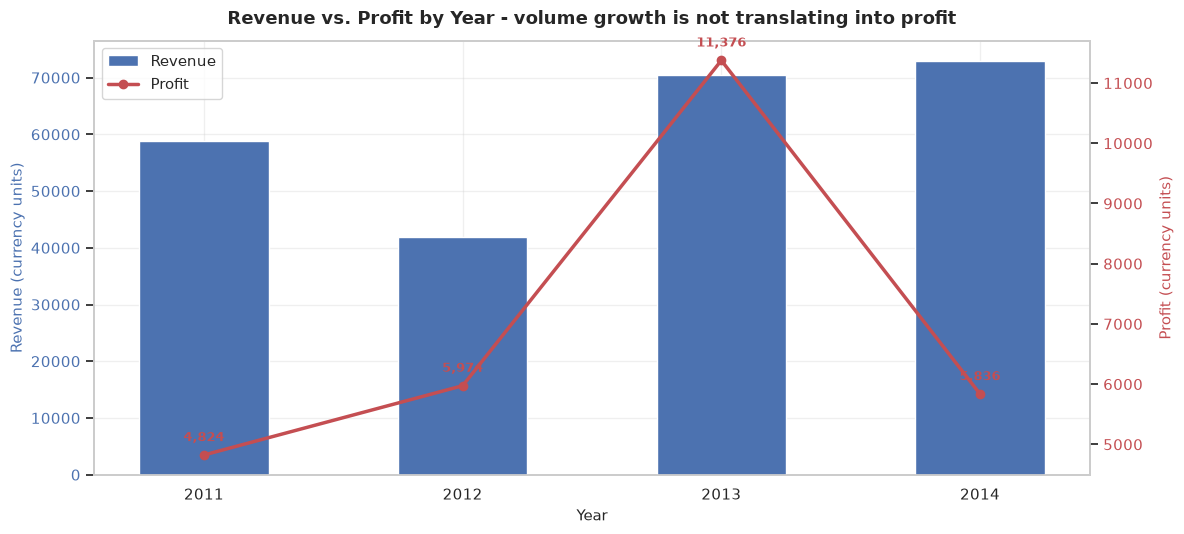

In [16]:
fig, ax1 = plt.subplots(figsize=(12, 5.5))

ax1.bar(yearly["Year"], yearly["Revenue"], width=0.5, color="#4c72b0",
        label="Revenue", zorder=3)
ax1.set_xlabel("Year")
ax1.set_ylabel("Revenue (currency units)", color="#4c72b0")
ax1.tick_params(axis="y", labelcolor="#4c72b0")
ax1.set_xticks(yearly["Year"])
ax1.zorder = 2
ax1.patch.set_visible(False)

ax2 = ax1.twinx()
ax2.plot(yearly["Year"], yearly["Profit"], color="#c44e52", marker="o",
         linewidth=2.5, label="Profit", zorder=4)
for x, y in zip(yearly["Year"], yearly["Profit"]):
    ax2.annotate(f"{y:,.0f}", (x, y), textcoords="offset points",
                 xytext=(0, 10), ha="center", fontsize=9, color="#c44e52", fontweight="bold")
ax2.set_ylabel("Profit (currency units)", color="#c44e52")
ax2.tick_params(axis="y", labelcolor="#c44e52")
ax2.grid(False)

ax1.set_title("Revenue vs. Profit by Year - volume growth is not translating into profit", pad=12)
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_revenue_vs_profit_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.2 Monthly sales trend

In [17]:
monthly = df.groupby("Month").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Order_Lines=("Order ID", "size"),
).reset_index()

monthly["Month"] = monthly["Month"].astype(str)
monthly = monthly.sort_values("Month").reset_index(drop=True)
monthly.to_csv(OUTPUT_DIR / "monthly_summary.csv", index=False)

print(f"Months covered: {len(monthly)}  ({monthly['Month'].min()} to {monthly['Month'].max()})")
print(f"Best month : {monthly.loc[monthly['Revenue'].idxmax(), 'Month']}  "
      f"revenue = {monthly['Revenue'].max():,.2f}")
print(f"Worst month: {monthly.loc[monthly['Revenue'].idxmin(), 'Month']}  "
      f"revenue = {monthly['Revenue'].min():,.2f}")
print(f"Revenue volatility (std / mean) = {monthly['Revenue'].std() / monthly['Revenue'].mean():.2f}")
print()
monthly.head(8).to_string(index=False)

Months covered: 48  (2011-01 to 2014-12)
Best month : 2014-11  revenue = 13,878.41
Worst month: 2012-02  revenue = 983.21
Revenue volatility (std / mean) = 0.55



'  Month  Revenue    Profit  Order_Lines\n2011-01 1,015.61    420.80            6\n2011-02 7,014.78  2,151.13            6\n2011-03 5,013.57    847.83           14\n2011-04 4,185.30    544.58           12\n2011-05 4,441.43     17.74           20\n2011-06 5,256.56    354.40           15\n2011-07 2,444.19 -3,732.65            4\n2011-08 4,827.38    735.54           21'

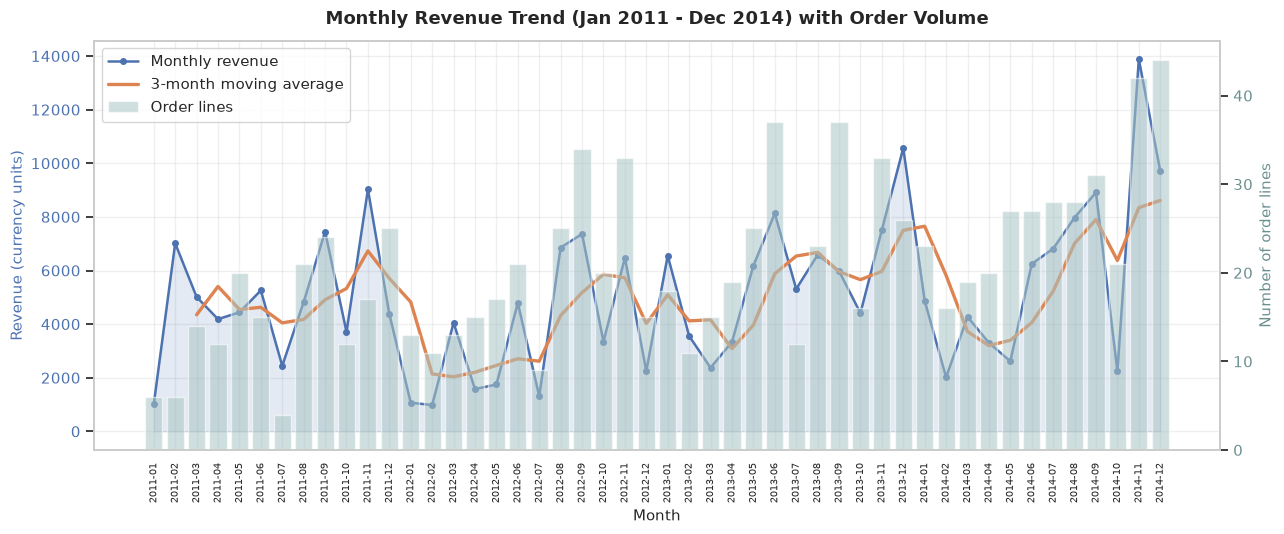

In [18]:
fig, ax1 = plt.subplots(figsize=(13, 5.5))

ax1.plot(monthly["Month"], monthly["Revenue"], color="#4c72b0", marker="o",
         markersize=4, linewidth=1.8, label="Monthly revenue")
ax1.set_xlabel("Month")
ax1.set_ylabel("Revenue (currency units)", color="#4c72b0")
ax1.tick_params(axis="y", labelcolor="#4c72b0")
ax1.tick_params(axis="x", rotation=90, labelsize=7)

# 3-month moving average to expose the underlying trend
monthly["Revenue_3M_MA"] = monthly["Revenue"].rolling(window=3).mean()
ax1.plot(monthly["Month"], monthly["Revenue_3M_MA"], color="#dd8452", linewidth=2.4,
         label="3-month moving average", zorder=5)
ax1.fill_between(monthly["Month"], monthly["Revenue"], alpha=0.15, color="#4c72b0")

ax2 = ax1.twinx()
ax2.bar(monthly["Month"], monthly["Order_Lines"], color="#a8c4c4", alpha=0.55,
        width=0.8, label="Order lines", zorder=1)
ax2.set_ylabel("Number of order lines", color="#6b8f8f")
ax2.tick_params(axis="y", labelcolor="#6b8f8f")
ax2.grid(False)

ax1.set_title("Monthly Revenue Trend (Jan 2011 - Dec 2014) with Order Volume", pad=12)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_monthly_sales_trend.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** Monthly revenue oscillates between 983 (Feb 2012) and 13,878 (Nov 2014) - a
**14.1x** range between the quietest and the busiest month, with a coefficient of variation of
0.55. The 3-month moving average (orange) makes the underlying upward trend visible underneath the
monthly noise.

**What pattern is visible.** Volatility is not constant. The coefficient of variation is 0.44 in
2011, 0.68 in 2012, 0.39 in 2013 and 0.59 in 2014, and the absolute monthly range is widest in
2014 (11,857 versus 6,381-8,191 in the earlier years). The most volatile years are the most
recent ones.

**An honest caveat on the obvious story:** it would be natural to assume the biggest months are
driven by the heaviest discounting, but this data does not support that. Monthly revenue
correlates **-0.10** with the average discount for that month, and the five biggest months
average a 15.7% discount against 14.0% in all other months - a difference far too small to
explain revenue swings of this size. The spikes are better explained by large individual orders
(the same long-tail effect seen in section 4) than by discount campaigns.

**Why it matters.** A business with 55% monthly revenue volatility cannot plan inventory, cash
flow or staffing from the annual total alone. The widening range in 2014 also means the revenue
base is becoming less predictable at the same time as margins are deteriorating.

### 8.3 Quarterly sales trend

In [19]:
quarterly = df.groupby("Quarter").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Order_Lines=("Order ID", "size"),
    Avg_Discount=("Discount", "mean"),
).reset_index()

quarterly["Margin %"] = (quarterly["Profit"] / quarterly["Revenue"] * 100).round(2)
quarterly["Quarter"] = quarterly["Quarter"].astype(str)
quarterly["Avg_Discount"] = (quarterly["Avg_Discount"] * 100).round(2)
quarterly.to_csv(OUTPUT_DIR / "quarterly_summary.csv", index=False)

print(quarterly.round(2).to_string(index=False))

Quarter   Revenue    Profit  Order_Lines  Avg_Discount  Margin %
 2011Q1 13,043.96  3,419.77           26         11.62     26.22
 2011Q2 13,883.29    916.71           47         16.94      6.60
 2011Q3 14,721.01 -1,619.81           49          8.92    -11.00
 2011Q4 17,115.05  2,107.12           54         13.41     12.31
 2012Q1  6,103.86    884.75           37         10.97     14.49
 2012Q2  8,119.36    439.64           53         14.85      5.41
 2012Q3 15,535.09  2,986.31           68         10.62     19.22
 2012Q4 12,075.99  1,663.18           68         17.71     13.77
 2013Q1 12,485.73  2,823.67           44         15.16     22.62
 2013Q2 17,638.88  1,975.47           81         18.11     11.20
 2013Q3 17,872.50  2,565.38           72         14.62     14.35
 2013Q4 22,493.12  4,011.21           75         11.80     17.83
 2014Q1 11,165.18 -1,541.55           58         16.76    -13.81
 2014Q2 12,167.41    923.88           74         15.38      7.59
 2014Q3 23,705.06  3,057.

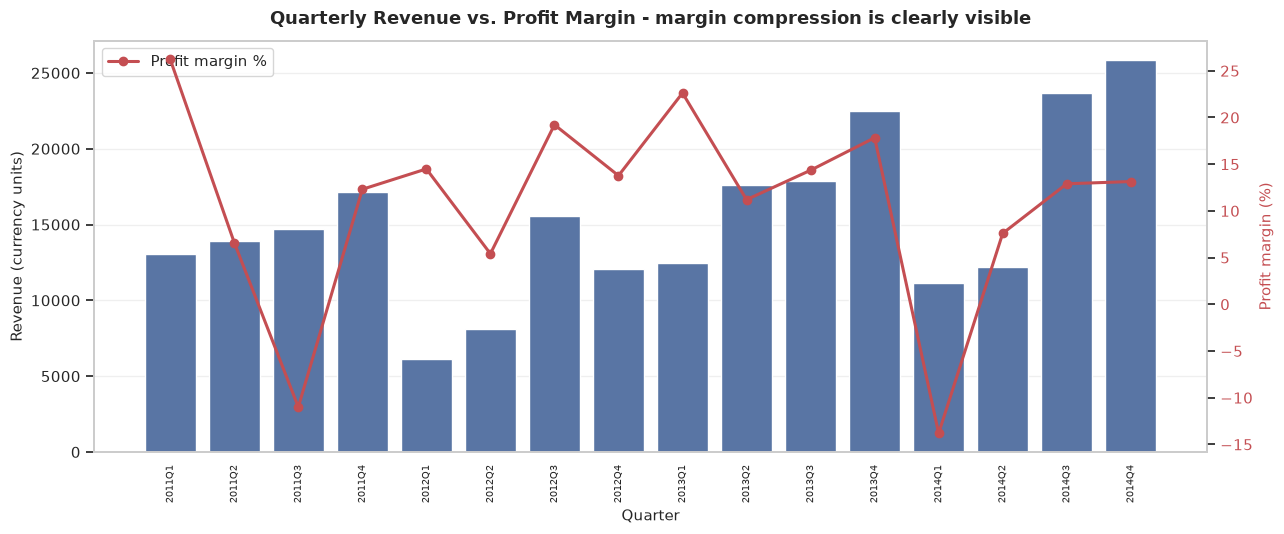

In [20]:
fig, ax = plt.subplots(figsize=(13, 5.5))

sns.barplot(data=quarterly, x="Quarter", y="Revenue", color="#4c72b0", ax=ax)
ax2 = ax.twinx()
ax2.plot(quarterly["Quarter"], quarterly["Margin %"], color="#c44e52", marker="o",
         linewidth=2.2, label="Profit margin %")
ax2.set_ylabel("Profit margin (%)", color="#c44e52")
ax2.tick_params(axis="y", labelcolor="#c44e52")
ax2.grid(False)

ax.set_title("Quarterly Revenue vs. Profit Margin - margin compression is clearly visible", pad=12)
ax.set_xlabel("Quarter")
ax.set_ylabel("Revenue (currency units)")
ax.tick_params(axis="x", rotation=90, labelsize=7)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_quarterly_revenue_and_margin.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** The margin line (red) is the important series here. Overall margin across
the whole period is 11.48%, but it is far from stable quarter to quarter: the best quarter runs
at **26.22%** (2011Q1) while the worst is **-13.81%** (2014Q1).

**What pattern is visible.** The highest-revenue quarter is never the highest-margin quarter. The
strongest revenue quarter of the period is 2014Q4 (25,835 revenue) at 13.14% margin, while the
best-margin quarter, 2011Q1 (26.22%), sits in the lowest-revenue band at 13,044. Ranking the
quarters by profit instead of revenue would surface an entirely different set of periods -
including 2011Q1, 2013Q1 (22.62%) and 2012Q3 (19.22%) - none of which are the top revenue
quarters.

**Why it matters.** This is direct evidence that the revenue ranking is a misleading way to
manage the business. Three of the top four revenue quarters (2014Q3, 2014Q4, 2013Q4) sit below
or near the 11.48% period average, so ranking by revenue would direct attention away from the
periods that actually create profit.

## 9. Customer Analysis

> **Data-availability note.** The dataset contains no `Age` and no `Gender` field, so an
> age-group distribution or a gender split cannot be produced without fabricating data. The
> analysis below uses the customer attributes that genuinely exist in the file.

### 9.1 Customer segment, market and region

In [21]:
segment = df.groupby("Segment").agg(
    Order_Lines=("Order ID", "size"),
    Customers=("Customer ID", "nunique"),
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
).reset_index()
segment["Share of Revenue %"] = (segment["Revenue"] / segment["Revenue"].sum() * 100).round(2)
segment["Margin %"] = (segment["Profit"] / segment["Revenue"] * 100).round(2)
segment["Revenue per Customer"] = (segment["Revenue"] / segment["Customers"]).round(2)
segment["Revenue"] = segment["Revenue"].round(2)
segment["Profit"] = segment["Profit"].round(2)
segment.to_csv(OUTPUT_DIR / "customer_segment_summary.csv", index=False)

print(segment.to_string(index=False))

    Segment  Order_Lines  Customers    Revenue    Profit  Share of Revenue %  Margin %  Revenue per Customer
   Consumer          536        343 128,296.90 11,856.29               52.59      9.24                374.04
  Corporate          273        183  59,768.53  8,645.25               24.50     14.46                326.60
Home Office          191        128  55,894.64  7,507.69               22.91     13.43                436.68


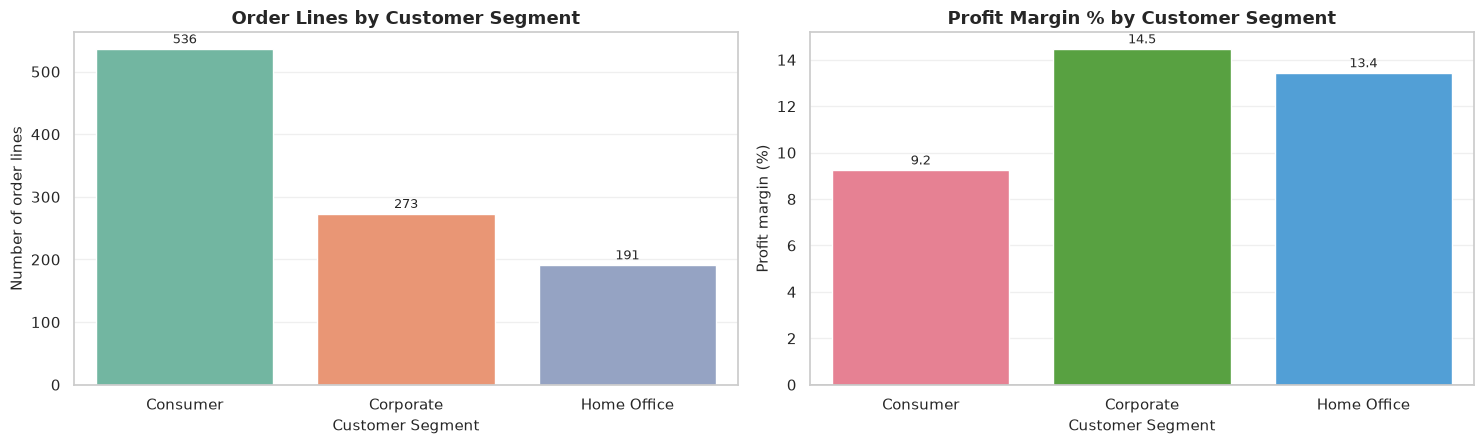

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

sns.barplot(data=segment, x="Segment", y="Order_Lines", palette=PALETTE, ax=axes[0])
axes[0].set_title("Order Lines by Customer Segment")
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Number of order lines")
for container in axes[0].containers:
    axes[0].bar_label(container, padding=2, fontsize=9)

sns.barplot(data=segment, x="Segment", y="Margin %", palette="husl", ax=axes[1])
axes[1].set_title("Profit Margin % by Customer Segment")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Profit margin (%)")
axes[1].axhline(0, color="black", linewidth=1)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f", padding=2, fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_customer_segment_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** `Consumer` customers account for 536 order lines (53.6%), `Corporate` 273
(27.3%) and `Home Office` 191 (19.1%). But the segments are **not** alike in value: `Home Office`
is the smallest segment by order lines yet earns the most per customer.

| Segment | Order lines | Customers | Revenue | Revenue share | Profit share | Margin | Revenue / customer |
|---|---|---|---|---|---|---|---|
| Consumer | 536 (53.6%) | 343 | 128,297 | 52.6% | 42.3% | **9.24%** | 374.04 |
| Corporate | 273 (27.3%) | 183 | 59,769 | 24.5% | 30.9% | **14.46%** | 326.60 |
| Home Office | 191 (19.1%) | 128 | 55,895 | 22.9% | 26.8% | **13.43%** | **436.68** |

**What pattern is visible.** Three different pictures emerge. `Consumer` supplies the volume and
over half the revenue, but at 9.24% it is the **least profitable** segment - and its 42.3% share
of profit is the *lowest* of the three, despite being the largest by every volume measure.
`Corporate` is the profitability winner at 14.46% margin on only 24.5% of revenue, so it is
systematically **under-indexed** relative to its margin quality. `Home Office` is the efficiency
winner, generating 436.68 per customer from the fewest customers.

**Why it matters.** Customer count alone must not be used to prioritise segments - doing so would
push effort towards `Consumer`, the least profitable segment. The evidence points the other way:
grow `Home Office` for revenue per customer, and shift commercial effort towards `Corporate`,
which converts revenue into profit better than any other segment.

### 9.2 Market and region performance

In [23]:
market = df.groupby("Market").agg(
    Order_Lines=("Order ID", "size"),
    Customers=("Customer ID", "nunique"),
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
).reset_index()
market["Margin %"] = (market["Profit"] / market["Revenue"] * 100).round(2)
market = market.sort_values("Revenue", ascending=False)
market.to_csv(OUTPUT_DIR / "market_summary.csv", index=False)

print(market.round(2).to_string(index=False))

Market  Order_Lines  Customers   Revenue   Profit  Margin %
  APAC          227        190 60,995.58 6,579.63     10.79
    EU          202        174 59,014.00 8,635.03     14.63
 LATAM          192        159 43,002.30 5,933.20     13.80
    US          196        178 40,714.16   571.18      1.40
  EMEA           89         82 17,315.16 1,820.73     10.52
Africa           88         78 16,464.00 2,176.92     13.22
Canada            6          6  6,454.86 2,292.54     35.52


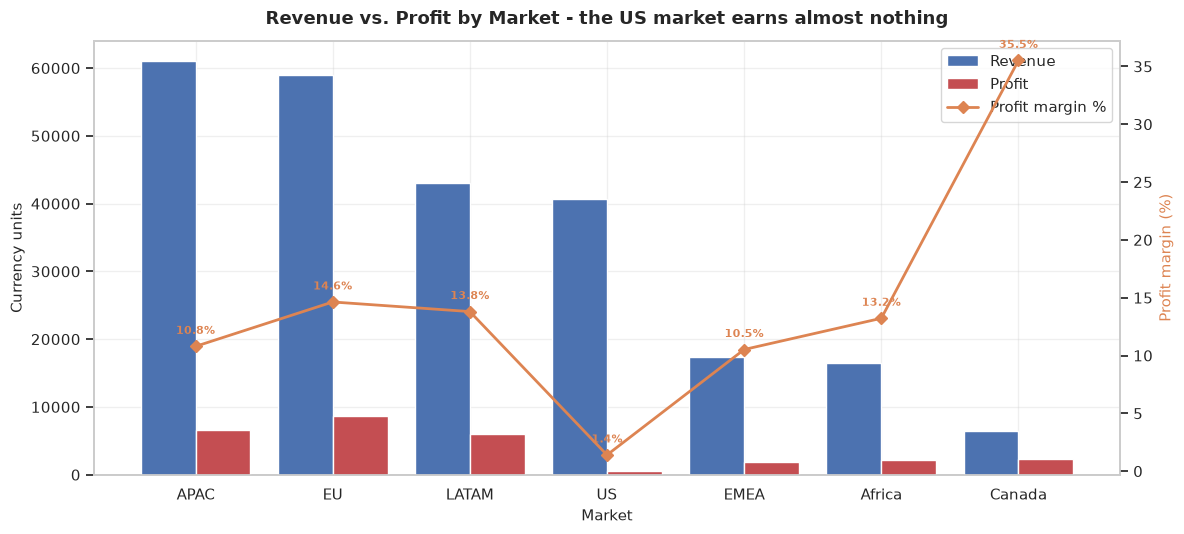

In [24]:
fig, ax1 = plt.subplots(figsize=(12, 5.5))

x = np.arange(len(market))
ax1.bar(x - 0.2, market["Revenue"], width=0.4, label="Revenue", color="#4c72b0", zorder=3)
ax1.bar(x + 0.2, market["Profit"], width=0.4, label="Profit", color="#c44e52", zorder=3)
ax1.axhline(0, color="black", linewidth=1)

ax1.set_xticks(x)
ax1.set_xticklabels(market["Market"])
ax1.set_xlabel("Market")
ax1.set_ylabel("Currency units")
ax1.set_title("Revenue vs. Profit by Market - the US market earns almost nothing", pad=12)

ax2 = ax1.twinx()
ax2.plot(x, market["Margin %"], color="#dd8452", marker="D", linewidth=2,
         label="Profit margin %", zorder=5)
for xi, yi in zip(x, market["Margin %"]):
    ax2.annotate(f"{yi:.1f}%", (xi, yi), textcoords="offset points", xytext=(0, 9),
                 ha="center", fontsize=8, color="#dd8452", fontweight="bold")
ax2.set_ylabel("Profit margin (%)", color="#dd8452")
ax2.grid(False)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_market_revenue_profit.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** This is one of the most commercially significant charts in the notebook. The
**US market is the fourth-largest by revenue** (40,714, 16.7% of total) but contributes only
**571 of profit - a 1.40% margin**. Every other market earns between 10.52% and 35.52%, so the US
earns less than **one seventh** of what EMEA manages (10.52%) and only 4% of Canada's 35.52%.

| Market | Revenue | Revenue share | Profit | Margin |
|---|---|---|---|---|
| APAC | 60,996 | 25.0% | 6,580 | 10.79% |
| EU | 59,014 | 24.2% | 8,635 | 14.63% |
| LATAM | 43,002 | 17.6% | 5,933 | 13.80% |
| **US** | 40,714 | 16.7% | **571** | **1.40%** |
| EMEA | 17,315 | 7.1% | 1,821 | 10.52% |
| Africa | 16,464 | 6.7% | 2,177 | 13.22% |
| Canada | 6,455 | 2.6% | 2,293 | **35.52%** |

**What pattern is visible.** Market size and market profitability are **negatively** related here
(Pearson r = -0.50 between market revenue and market margin). The clearest extremes point the same
way: `Canada` is the *smallest* market by revenue (2.6%) and by far the most profitable (35.52%),
while the `US` is the fourth largest and the least profitable (1.40%).

**A caveat that matters for action:** the US weakness is concentrated in the earlier years, not
recently. US margin by year is -7.91% (2011), 9.09% (2012), 1.52% (2013) and **20.03% (2014)**, so
2014 is the US's strongest year by a wide margin and its revenue share actually fell to 9.3%. The
US margin problem is real for the period as a whole but is not deteriorating.

**Why it matters.** The US is quietly consuming delivery, handling and discount cost at a far
higher rate than its margin can support. This is the clearest example of why revenue alone is a
poor KPI for this business.

### 9.3 Repeat purchasing behaviour

In [25]:
customer_orders = df.groupby("Customer ID").agg(
    Orders=("Order ID", "nunique"),
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
)
customer_orders["Segment"] = df.groupby("Customer ID")["Segment"].agg(lambda s: s.mode().iat[0])

repeat_customers = (customer_orders["Orders"] > 1).sum()
print(f"Total customers           : {len(customer_orders):,}")
print(f"Customers with >1 order    : {repeat_customers:,} "
      f"({repeat_customers / len(customer_orders) * 100:.1f}%)")
print(f"Customers with a single order: {len(customer_orders) - repeat_customers:,} "
      f"({(len(customer_orders) - repeat_customers) / len(customer_orders) * 100:.1f}%)")
print(f"Average orders per customer: {customer_orders['Orders'].mean():.2f}")
print(f"Maximum orders by a customer: {customer_orders['Orders'].max()}")

repeat_profile = customer_orders.assign(
    Type=np.where(customer_orders["Orders"] > 1, "Repeat (2+ orders)", "One-time")
).groupby("Type").agg(
    Customers=("Orders", "size"),
    Avg_Revenue=("Revenue", "mean"),
    Avg_Orders=("Orders", "mean"),
    Avg_Profit=("Profit", "mean"),
)
repeat_profile["Avg_Revenue"] = repeat_profile["Avg_Revenue"].round(2)
repeat_profile["Avg_Profit"] = repeat_profile["Avg_Profit"].round(2)
print()
print(repeat_profile.to_string())

Total customers           : 654
Customers with >1 order    : 229 (35.0%)
Customers with a single order: 425 (65.0%)
Average orders per customer: 1.50
Maximum orders by a customer: 6

                    Customers  Avg_Revenue  Avg_Orders  Avg_Profit
Type                                                              
One-time                  425       229.29        1.00       12.80
Repeat (2+ orders)        229       639.79        2.42       98.56


**What this shows.** 654 distinct customers place 979 orders, i.e. only **1.50 orders per
customer**, and **65.0% of customers (425 of 654) never order again**. A repeat customer
generates **2.79x** the total revenue of a one-time customer - and 1.12x the revenue per
individual order, so the gap is driven mainly by returning more often rather than by spending
more when they do.

**Why it matters.** The customer base is dominated by one-time buyers. Retention, not
acquisition, is the largest untapped revenue pool in this dataset - more than half of all
customers are dormant after a single transaction, and the 425 that never return are the single
largest block of unrealised value identified anywhere in this analysis.

## 10. Product Analysis

### 10.1 Top 10 best-selling products by quantity

In [26]:
top_qty = df.groupby("Product Name").agg(
    Quantity=("Quantity", "sum"),
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Order_Lines=("Order ID", "size"),
).sort_values("Quantity", ascending=False).head(10).reset_index()
top_qty["Margin %"] = (top_qty["Profit"] / top_qty["Revenue"] * 100).round(2)
top_qty[["Revenue", "Profit"]] = top_qty[["Revenue", "Profit"]].round(2)
top_qty.to_csv(OUTPUT_DIR / "top10_products_by_quantity.csv", index=False)

print(top_qty.to_string(index=False))

                                        Product Name  Quantity  Revenue    Profit  Order_Lines  Margin %
               Stockwell Paper Clips, Assorted Sizes        22   194.06     13.76            4      7.09
                Sterilite Officeware Hinged File Box        15   146.72     31.96            3     21.79
                       Acme Letter Opener, Easy Grip        14   341.64    108.92            2     31.88
                       Avery Binder Covers, Recycled        14   157.73     57.77            2     36.63
  Harbour Creations Removable Labels, 5000 Label Set        14   130.41     28.77            1     22.06
                            Stanley Sketch Pad, Blue        14   562.78    157.04            3     27.90
                          Breville Microwave, Silver        14 2,117.22 -1,736.28            1    -82.01
                     Nokia Signal Booster, Full Size        13 1,791.27    404.94            2     22.61
Novimex File Folder Labels, Laser Printer Compatible   

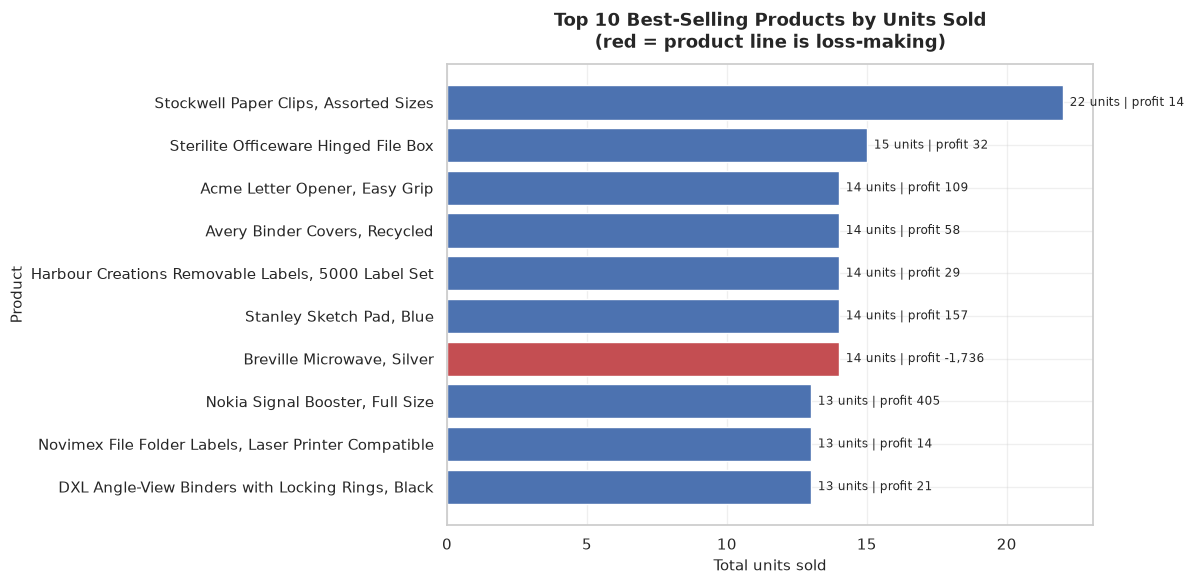

In [27]:
fig, ax = plt.subplots(figsize=(12, 6))

colors = ["#c44e52" if p < 0 else "#4c72b0" for p in top_qty["Profit"]]
ax.barh(top_qty["Product Name"][::-1], top_qty["Quantity"][::-1], color=colors[::-1])
ax.set_title("Top 10 Best-Selling Products by Units Sold\n(red = product line is loss-making)", pad=12)
ax.set_xlabel("Total units sold")
ax.set_ylabel("Product")
for i, (q, p) in enumerate(zip(top_qty["Quantity"][::-1], top_qty["Profit"][::-1])):
    ax.text(q + 0.25, i, f"{q} units | profit {p:,.0f}", va="center", fontsize=8.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_top10_products_by_quantity.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** The best-seller by volume is *Stockwell Paper Clips, Assorted Sizes*
(22 units), followed by office storage and stationery items. The top of the list is entirely
low-value consumables.

**What pattern is visible — and it is not the expected one.** The 7th best-selling product,
**Breville Microwave, Silver**, sold 14 units for 2,117 in revenue but produced a **loss of
-1,736**, a margin of **-82.0%**. Volume leadership and value creation are almost completely
decoupled here.

**Why it matters.** Stock-based and promotional decisions must never be made on units sold
alone. A high-volume line can be the single most destructive line in the portfolio, and a
volume-ranked report would have ranked this microwave almost as highly as paper clips.

### 10.2 Top 10 products by revenue

In [28]:
top_rev = df.groupby("Product Name").agg(
    Quantity=("Quantity", "sum"),
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
).sort_values("Revenue", ascending=False).head(10).reset_index()
top_rev["Margin %"] = (top_rev["Profit"] / top_rev["Revenue"] * 100).round(2)
top_rev[["Revenue", "Profit"]] = top_rev[["Revenue", "Profit"]].round(2)
top_rev.to_csv(OUTPUT_DIR / "top10_products_by_revenue.csv", index=False)

print(top_rev.to_string(index=False))

                                            Product Name  Quantity  Revenue    Profit  Margin %
                         Motorola Smart Phone, Full Size        11 7,083.78  2,124.87     30.00
               GBC DocuBind P400 Electric Binding System        11 5,443.96 -2,640.32    -48.50
                 SAFCO Executive Leather Armchair, Black        11 4,544.10  1,868.13     41.11
                    Motorola Smart Phone, with Caller ID         7 4,518.78    632.52     14.00
                            Nokia Smart Phone, Full Size         9 4,247.28    959.48     22.59
                   DMI Eclipse Executive Suite Bookcases        10 4,007.84    -50.10     -1.25
Harbour Creations Executive Leather Armchair, Adjustable        11 3,747.91    741.64     19.79
                           Sauder Classic Bookcase, Pine         8 3,498.72    594.72     17.00
                        Hamilton Beach Refrigerator, Red         6 3,000.78  1,080.18     36.00
                      Bush Classic Bookc

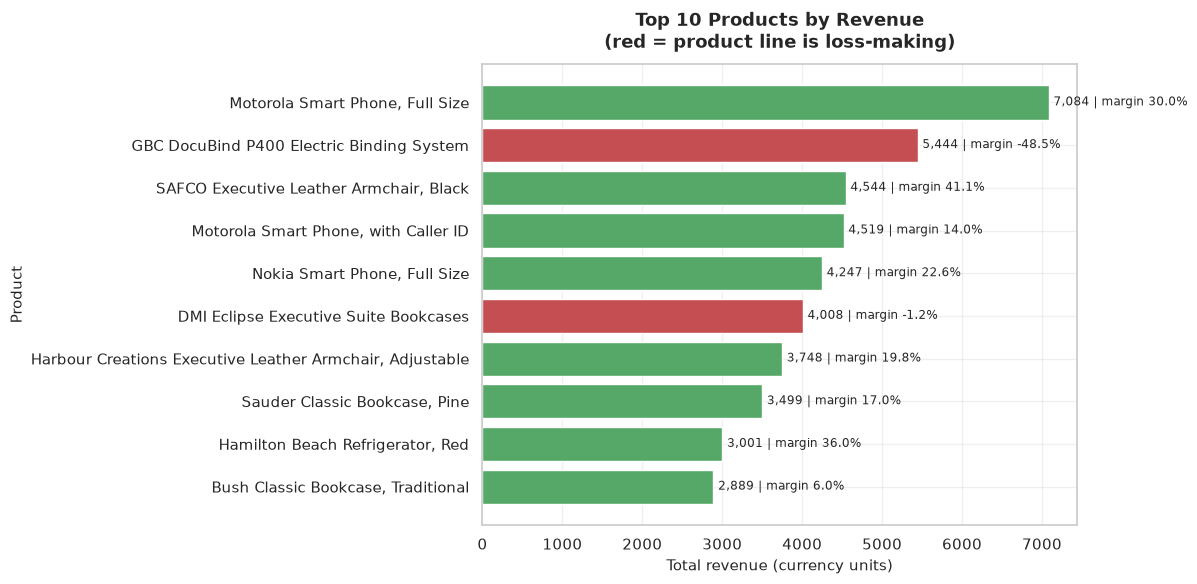

In [29]:
fig, ax = plt.subplots(figsize=(12, 6))

colors = ["#c44e52" if p < 0 else "#55a868" for p in top_rev["Profit"]]
ax.barh(top_rev["Product Name"][::-1], top_rev["Revenue"][::-1], color=colors[::-1])
ax.set_title("Top 10 Products by Revenue\n(red = product line is loss-making)", pad=12)
ax.set_xlabel("Total revenue (currency units)")
ax.set_ylabel("Product")
for i, (r, m) in enumerate(zip(top_rev["Revenue"][::-1], top_rev["Margin %"][::-1])):
    ax.text(r + 60, i, f"{r:,.0f} | margin {m:.1f}%", va="center", fontsize=8.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "09_top10_products_by_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** Revenue leadership points at a completely different portfolio from volume
leadership. The top six products by revenue are two Motorola smart phones, a Nokia smart phone, a
GBC DocuBind binding system, a SAFCO leather armchair and DMI bookcases - **three of the six are
Technology**, and the single largest line (*Motorola Smart Phone, Full Size*, 7,084) is a
Technology item worth more than the entire top-10 volume list combined.

| Rank | Product | Category | Revenue |
|---|---|---|---|
| 1 | Motorola Smart Phone, Full Size | Technology | 7,084 |
| 2 | GBC DocuBind P400 Electric Binding System | Office Supplies | 5,444 |
| 3 | SAFCO Executive Leather Armchair, Black | Furniture | 4,544 |
| 4 | Motorola Smart Phone, with Caller ID | Technology | 4,519 |
| 5 | Nokia Smart Phone, Full Size | Technology | 4,247 |
| 6 | DMI Eclipse Executive Suite Bookcases | Furniture | 4,008 |

Note that the revenue ranking is **not** a clean Technology sweep - second place is an Office
Supplies binding machine and third is a Furniture armchair - so "Technology dominates revenue" is
too simple a statement. What is true is that the very top of the list is technology-led and
dominated by a handful of high-value items. The price gap is extreme: a Motorola Smart Phone
averages 643.98 per unit against 8.82 for the volume-leading *Stockwell Paper Clips* - a **73x**
difference.

**Why it matters.** Volume leadership and revenue leadership point at completely different product
portfolios. The business needs **two separate strategies** - a high-frequency, low-margin
consumables stream for traffic, and a high-value technology stream for revenue - rather than one
undifferentiated "top products" list.

### 10.3 Revenue and profit by category

In [30]:
category = df.groupby("Category").agg(
    Order_Lines=("Order ID", "size"),
    Quantity=("Quantity", "sum"),
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
).sort_values("Revenue", ascending=False).reset_index()
category["Margin %"] = (category["Profit"] / category["Revenue"] * 100).round(2)
category["Revenue Share %"] = (category["Revenue"] / category["Revenue"].sum() * 100).round(2)
category["Profit Share %"] = (category["Profit"] / category["Profit"].sum() * 100).round(2)
category[["Revenue", "Profit"]] = category[["Revenue", "Profit"]].round(2)
category.to_csv(OUTPUT_DIR / "category_summary.csv", index=False)

print(category.to_string(index=False))

       Category  Order_Lines  Quantity   Revenue    Profit  Margin %  Revenue Share %  Profit Share %
      Furniture          194       654 86,018.56 10,773.65     12.52            35.26           38.46
     Technology          186       624 81,129.41 11,938.71     14.72            33.26           42.62
Office Supplies          620      2110 76,812.09  5,296.87      6.90            31.49           18.91


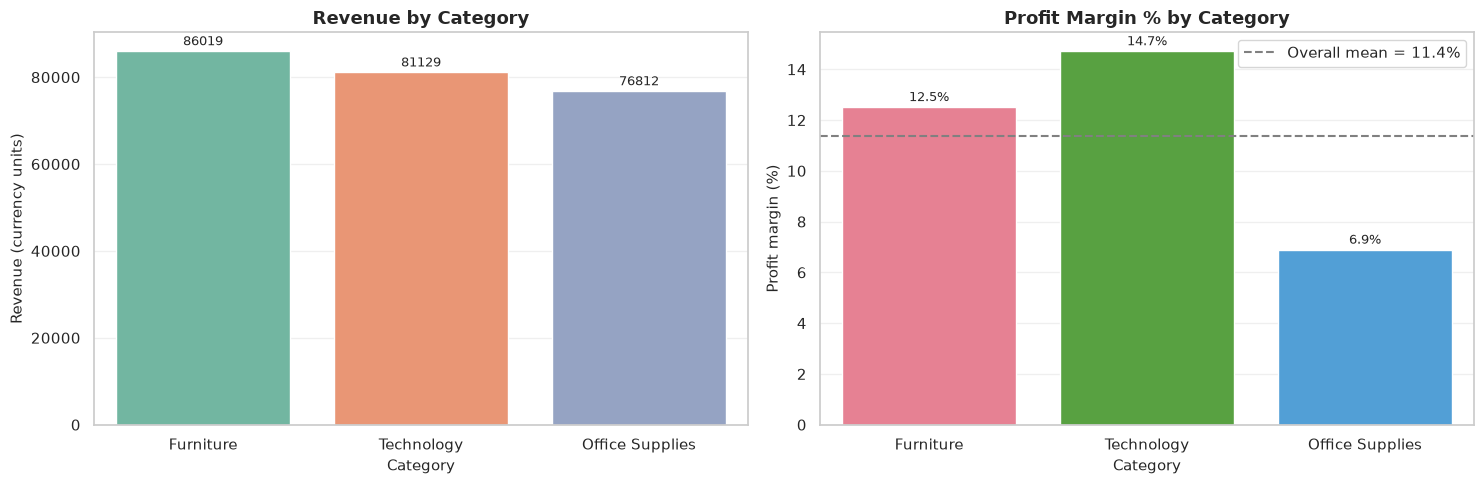

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=category, x="Category", y="Revenue", palette=PALETTE, ax=axes[0])
axes[0].set_title("Revenue by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Revenue (currency units)")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=2, fontsize=9)

sns.barplot(data=category, x="Category", y="Margin %", palette="husl", ax=axes[1])
axes[1].set_title("Profit Margin % by Category")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Profit margin (%)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=2, fontsize=9)
axes[1].axhline(category["Margin %"].mean(), color="grey", linestyle="--",
                label=f"Overall mean = {category['Margin %'].mean():.1f}%")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "10_revenue_and_margin_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** The three categories are almost identical in revenue (86,019 / 81,129 /
76,812 - a spread of only 12% across the whole portfolio) but very different in profitability:
Technology earns **14.72%**, Furniture 12.52% and Office Supplies only **6.90%**.

| Category | Order lines | Line share | Revenue | Profit | Profit share | Margin |
|---|---|---|---|---|---|---|
| Office Supplies | 620 | **62.0%** | 76,812 | 5,297 | **18.9%** | **6.90%** |
| Furniture | 194 | 19.4% | 86,019 | 10,774 | 38.5% | 12.52% |
| Technology | 186 | **18.6%** | 81,129 | 11,939 | **42.6%** | **14.72%** |

**What pattern is visible.** `Office Supplies` accounts for **62.0% of all order lines but only
18.9% of profit**, while `Technology` accounts for just 18.6% of order lines yet delivers
**42.6% of all profit** - and Technology earns more profit than the other two categories combined
despite the smallest order volume of the three by a factor of three.

**Why it matters.** This is the strongest argument in the whole analysis for shifting commercial
effort towards Technology. A business that managed its categories purely by transaction volume
would put nearly two thirds of its effort behind the category generating less than a fifth of
its profit.

### 10.4 Sub-category margin ranking (where value is destroyed)

In [32]:
subcat = df.groupby(["Category", "Sub-Category"]).agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Order_Lines=("Order ID", "size"),
).reset_index()
subcat["Margin %"] = (subcat["Profit"] / subcat["Revenue"] * 100).round(2)
subcat = subcat.sort_values("Margin %")
subcat.to_csv(OUTPUT_DIR / "subcategory_margin.csv", index=False)

print("Worst 6 sub-categories by margin:")
print(subcat.head(6).round(2).to_string(index=False))
print()
print("Best 6 sub-categories by margin:")
print(subcat.tail(6).round(2).to_string(index=False))

Worst 6 sub-categories by margin:
       Category Sub-Category   Revenue    Profit  Order_Lines  Margin %
Office Supplies      Binders 13,946.33 -2,088.97          121    -14.98
      Furniture       Tables 14,454.41     -2.88           20     -0.02
Office Supplies      Storage 17,175.74    936.58          102      5.45
     Technology      Copiers 21,319.59  1,522.64           37      7.14
Office Supplies    Fasteners  1,554.90    124.52           54      8.01
Office Supplies          Art  7,990.02    859.44           96     10.76

Best 6 sub-categories by margin:
       Category Sub-Category   Revenue   Profit  Order_Lines  Margin %
      Furniture       Chairs 31,613.14 4,847.62           71     15.33
Office Supplies    Envelopes  3,179.69   543.00           45     17.08
Office Supplies        Paper  3,672.89   651.83           65     17.75
      Furniture  Furnishings  7,672.69 1,481.73           59     19.31
     Technology       Phones 39,246.59 7,616.08           71     19.41
Of

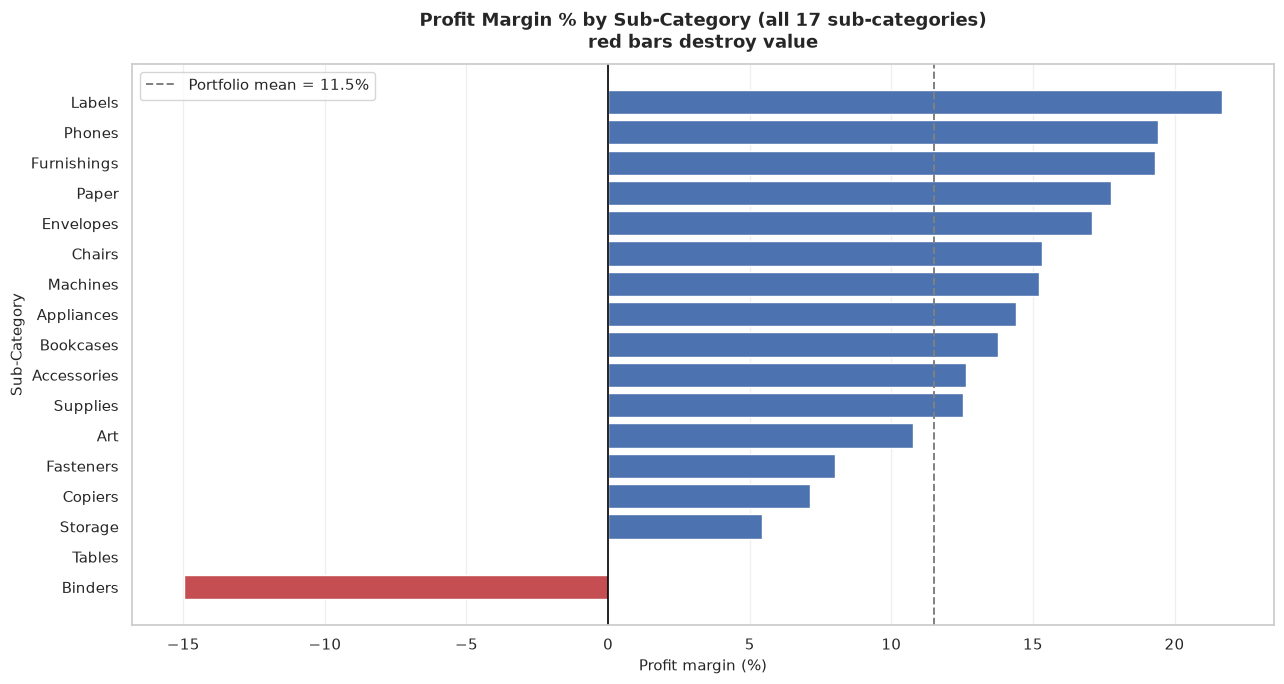

In [33]:
fig, ax = plt.subplots(figsize=(13, 7))

plot_df = subcat.sort_values("Margin %")
bar_colors = ["#c44e52" if m < 0 else "#4c72b0" for m in plot_df["Margin %"]]
ax.barh(plot_df["Sub-Category"], plot_df["Margin %"], color=bar_colors)
ax.axvline(0, color="black", linewidth=1.2)
ax.axvline(subcat["Margin %"].mean(), color="grey", linestyle="--", linewidth=1.4,
           label=f"Portfolio mean = {subcat['Margin %'].mean():.1f}%")

ax.set_title("Profit Margin % by Sub-Category (all 17 sub-categories)\n"
             "red bars destroy value", pad=12)
ax.set_xlabel("Profit margin (%)")
ax.set_ylabel("Sub-Category")
ax.legend(frameon=True)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "11_subcategory_margin.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** `Binders` is the single worst sub-category: 13,946 of revenue producing a
loss of **-2,089 (-14.98% margin)**. `Tables` is effectively break-even at -0.02%. At the other
end, `Labels` earns 21.68% and `Phones` 19.41%, while 15 of the 17 sub-categories sit above the
11.48% portfolio mean.

**What pattern is visible - and the size needs stating precisely.** `Binders` generates 5.7% of
total revenue and destroys 2,089 of profit. Set against the right denominator that is still a
large number: the loss is **39% of the entire 5,297 profit** generated by the whole Office Supplies
category, and **7.5% of net company profit** (and 10.1% of all profit lost across loss-making
lines). It is a genuine single-SKU-category problem, but it is *not* the dominant driver of
company-level losses - the deep-discount band identified in section 12 is roughly twice as large.

**Why it matters.** A sub-category responsible for 39% of an entire category's profit, and 10% of
all losses, is worth fixing or exiting. It is a high-leverage, low-cost action precisely because
the fix is a single supplier negotiation or SKU rationalisation rather than a portfolio-wide
programme - but it should be ranked behind the 20% discount cap, which is worth about twice as
much.

## 11. Correlation Analysis

The correlation matrix is computed on the numeric business variables to see which ones move
together and which are independent.

In [34]:
corr_cols = ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost", "Delivery Days", "Unit Price"]
corr_matrix = df[corr_cols].corr()

print("Correlation matrix:")
print(corr_matrix.round(3).to_string())

Correlation matrix:
               Sales  Quantity  Discount  Profit  Shipping Cost  Delivery Days  Unit Price
Sales           1.00      0.31     -0.10    0.41           0.88          -0.01        0.82
Quantity        0.31      1.00      0.01    0.04           0.25           0.01       -0.00
Discount       -0.10      0.01      1.00   -0.33          -0.09          -0.01       -0.13
Profit          0.41      0.04     -0.33    1.00           0.40           0.00        0.40
Shipping Cost   0.88      0.25     -0.09    0.40           1.00          -0.12        0.73
Delivery Days  -0.01      0.01     -0.01    0.00          -0.12           1.00       -0.02
Unit Price      0.82     -0.00     -0.13    0.40           0.73          -0.02        1.00


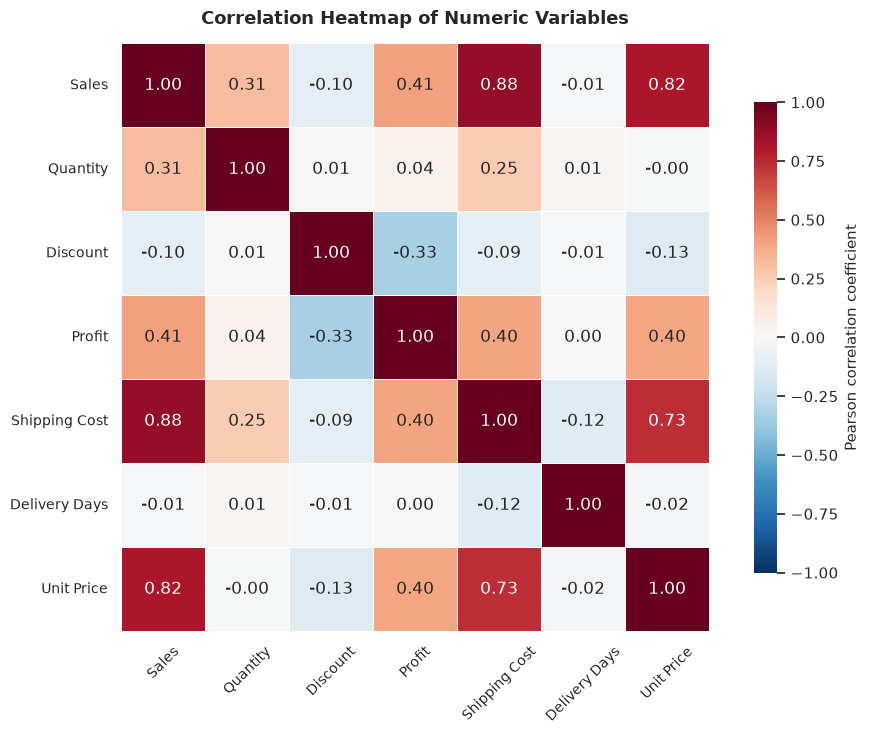

In [35]:
fig, ax = plt.subplots(figsize=(10, 7.5))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.6,
            cbar_kws={"shrink": 0.8, "label": "Pearson correlation coefficient"})

ax.set_title("Correlation Heatmap of Numeric Variables", pad=14, fontsize=13, fontweight="bold")
ax.tick_params(axis="x", rotation=45, labelsize=10)
ax.tick_params(axis="y", rotation=0, labelsize=10)
ax.grid(False)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "12_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** Three relationships stand out:

| Pair | r | Strength |
|---|---|---|
| Sales vs. Shipping Cost | **+0.88** | very strong |
| Sales vs. Profit | +0.41 | moderate |
| Discount vs. Profit | **-0.33** | moderate, negative |
| Sales / Discount / Profit vs. Delivery Days | ~0.00 | **none** |

**What pattern is visible.** Sales and shipping cost are almost perfectly locked together, while
delivery speed has essentially **no** relationship with revenue, profit or discount. Also notable:
`Quantity` correlates with `Sales` at only 0.31, which means unit price — not volume — drives
order value in this portfolio.

**Why it matters.** Two practical conclusions follow. First, shipping cost behaves as a
*proportional* cost that must be modelled as a percentage of order value, not as a fixed fee,
because it scales almost one-for-one with revenue. Second, paying for faster delivery buys
**no measurable revenue or profit benefit here** — the premium shipping spend cannot be
justified by faster delivery on these figures.

## 12. Additional Analysis - The Discount-Profit Relationship

This section investigates the single most important pattern in the dataset. The requirement for
a non-obvious insight is met by the **threshold effect** revealed below: the relationship between
discount and margin is not linear, and there is a clear break point.

In [36]:
discount_bands = pd.cut(
    df["Discount"],
    bins=[-0.001, 0.0, 0.10, 0.20, 0.30, 1.00],
    labels=["0% (no discount)", "1-10%", "11-20%", "21-30%", "31%+"],
)
discount_bands.name = "Discount band"
band_profile = df.groupby(discount_bands, observed=True).agg(
    Order_Lines=("Order ID", "size"),
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Order_Value=("Sales", "mean"),
).reset_index()

band_profile["Share of Lines %"] = (band_profile["Order_Lines"] / len(df) * 100).round(2)
band_profile["Margin %"] = (band_profile["Profit"] / band_profile["Revenue"] * 100).round(2)
band_profile[["Revenue", "Profit", "Avg_Order_Value"]] = band_profile[
    ["Revenue", "Profit", "Avg_Order_Value"]
].round(2)
band_profile.to_csv(OUTPUT_DIR / "discount_band_analysis.csv", index=False)

print(band_profile.to_string(index=False))

   Discount band  Order_Lines    Revenue     Profit  Avg_Order_Value  Share of Lines %  Margin %
0% (no discount)          564 145,756.86  36,971.77           258.43             56.40     25.37
           1-10%           96  32,823.01   7,044.97           341.91              9.60     21.46
          11-20%          112  29,758.72   3,028.68           265.70             11.20     10.18
          21-30%           19   5,003.12    -793.21           263.32              1.90    -15.85
            31%+          209  30,618.35 -18,242.98           146.50             20.90    -59.58


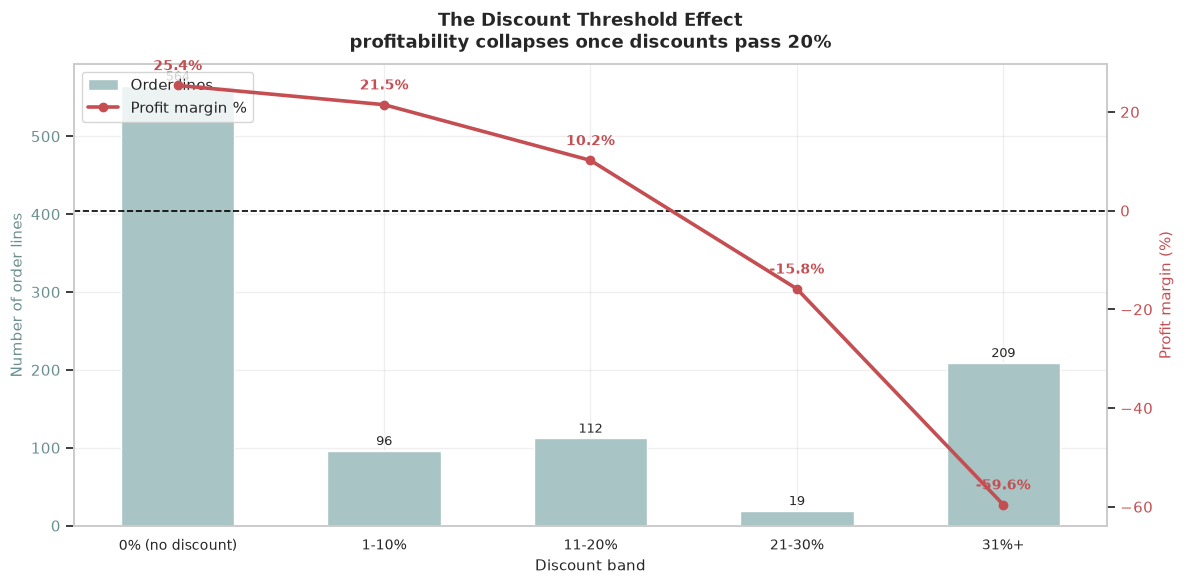

In [37]:
fig, ax1 = plt.subplots(figsize=(12, 6))

x = np.arange(len(band_profile))
ax1.bar(x, band_profile["Order_Lines"], width=0.55, color="#a8c4c4",
        label="Order lines", zorder=3)
ax1.set_xlabel("Discount band")
ax1.set_ylabel("Number of order lines", color="#6b8f8f")
ax1.set_xticks(x)
ax1.set_xticklabels(band_profile["Discount band"], fontsize=10)
ax1.tick_params(axis="y", labelcolor="#6b8f8f")
ax1.set_zorder(1)
ax1.patch.set_visible(False)
for container in ax1.containers:
    ax1.bar_label(container, padding=2, fontsize=9)

ax2 = ax1.twinx()
ax2.plot(x, band_profile["Margin %"], color="#c44e52", marker="o", linewidth=2.6,
         label="Profit margin %", zorder=5)
ax2.axhline(0, color="black", linewidth=1.2, linestyle="--")
ax2.set_ylabel("Profit margin (%)", color="#c44e52")
ax2.tick_params(axis="y", labelcolor="#c44e52")
ax2.grid(False)
for xi, yi in zip(x, band_profile["Margin %"]):
    ax2.annotate(f"{yi:.1f}%", (xi, yi), textcoords="offset points", xytext=(0, 11),
                 ha="center", fontsize=10, color="#c44e52", fontweight="bold")

ax1.set_title("The Discount Threshold Effect\n"
              "profitability collapses once discounts pass 20%", pad=12, fontsize=13)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "13_discount_threshold_effect.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** Order lines (grey bars) are heavily concentrated at 0% discount (56.4%) and
at 31%+ (20.9%) - almost nobody sits in the middle bands. The margin line (red) shows a
**sharp, non-linear collapse**:

| Discount band | Order lines | Revenue | Profit | Margin % | Avg profit / line |
|---|---|---|---|---|---|
| 0% (no discount) | 564 | 145,757 | 36,972 | **+25.37%** | +65.55 |
| 1-10% | 96 | 32,823 | 7,045 | +21.46% | +73.39 |
| 11-20% | 112 | 29,759 | 3,029 | +10.18% | +27.04 |
| 21-30% | 19 | 5,003 | -793 | **-15.85%** | -41.75 |
| 31%+ | 209 | 30,618 | -18,243 | **-59.58%** | -87.29 |

**What pattern is visible - the non-obvious insight.** Discounts up to 20% still make money, but
**beyond 20% the business loses money on every single order**, and beyond 30% it loses almost 60
cents for every currency unit of revenue. Critically, this is *not* a smooth decay: the drop from
the 11-20% band (+10.18%) to the 21-30% band (-15.85%) is a **26 percentage point cliff**. The
1-10% band actually earns the highest profit *per line* (+73.39) of any band - a small discount
appears to improve conversion without damaging unit economics, whereas anything past 20%
destroys value on every transaction.

**Why it matters.** This converts a vague "discounting is risky" concern into an actionable
operating rule: **cap automatic discounts at 20% and require managerial approval beyond that**.
The 21%+ bands are only 228 order lines (22.8% of the file) but destroy 19,036 of profit - **68%
of the company's entire net profit of 28,009**. The entire rest of the business, on the
remaining 772 lines, is what funds that loss.

In [38]:
# Quantify exactly how much profit the deep-discount band destroys
deep = band_profile[band_profile["Discount band"] == "31%+"].iloc[0]
total_profit = df["Profit"].sum()

print(f"Total company profit                : {total_profit:,.2f}")
print(f"Profit lost in the 31%+ band        : {deep['Profit']:,.2f}")
print(f"Share of the 31%+ band of all lines : {deep['Share of Lines %']:.1f}%")
print(f"...which wipes out                  : {abs(deep['Profit']) / total_profit * 100:.1f}% of total profit")
print(f"Order lines with discount > 20%     : {int((df['Discount'] > 0.20).sum())}")
print(f"Profit from those lines             : {df.loc[df['Discount'] > 0.20, 'Profit'].sum():,.2f}")
print()
print("Sanity check - what the business would earn without any discount above 20%:")
print(f"  {df.loc[df['Discount'] <= 0.20, 'Profit'].sum():,.2f} "
      f"(vs. {df['Profit'].sum():,.2f} actual)")

Total company profit                : 28,009.23
Profit lost in the 31%+ band        : -18,242.98
Share of the 31%+ band of all lines : 20.9%
...which wipes out                  : 65.1% of total profit
Order lines with discount > 20%     : 228
Profit from those lines             : -19,036.19

Sanity check - what the business would earn without any discount above 20%:
  47,045.42 (vs. 28,009.23 actual)


### 12.2 Where do the loss-making orders actually come from?

In [39]:
loss = df[df["Profit"] < 0]
print(f"Loss-making order lines : {len(loss)} of {len(df)} ({len(loss) / len(df) * 100:.1f}%)")
print(f"Total loss              : {loss['Profit'].sum():,.2f}")
print(f"Total profit from the other {len(df) - len(loss)} lines: "
      f"{df.loc[df['Profit'] >= 0, 'Profit'].sum():,.2f}")
print()
print("Loss-making lines by category:")
print(loss.groupby("Category").agg(
    Lines=("Profit", "size"),
    Loss=("Profit", "sum"),
    Avg_Discount=("Discount", "mean"),
).assign(Avg_Discount=lambda d: (d["Avg_Discount"] * 100).round(1)).to_string())
print()
print("Share of loss-making lines that carry a discount above 20%:")
print(f"  {(loss['Discount'] > 0.20).mean() * 100:.1f}%")
print(f"Share of ALL lines with a discount above 20%: {(df['Discount'] > 0.20).mean() * 100:.1f}%")

Loss-making order lines : 255 of 1000 (25.5%)
Total loss              : -20,722.57
Total profit from the other 745 lines: 48,731.80

Loss-making lines by category:
                 Lines      Loss  Avg_Discount
Category                                      
Furniture           52 -5,352.72         40.00
Office Supplies    151 -9,999.74         46.60
Technology          52 -5,370.11         42.20

Share of loss-making lines that carry a discount above 20%:
  81.2%
Share of ALL lines with a discount above 20%: 22.8%


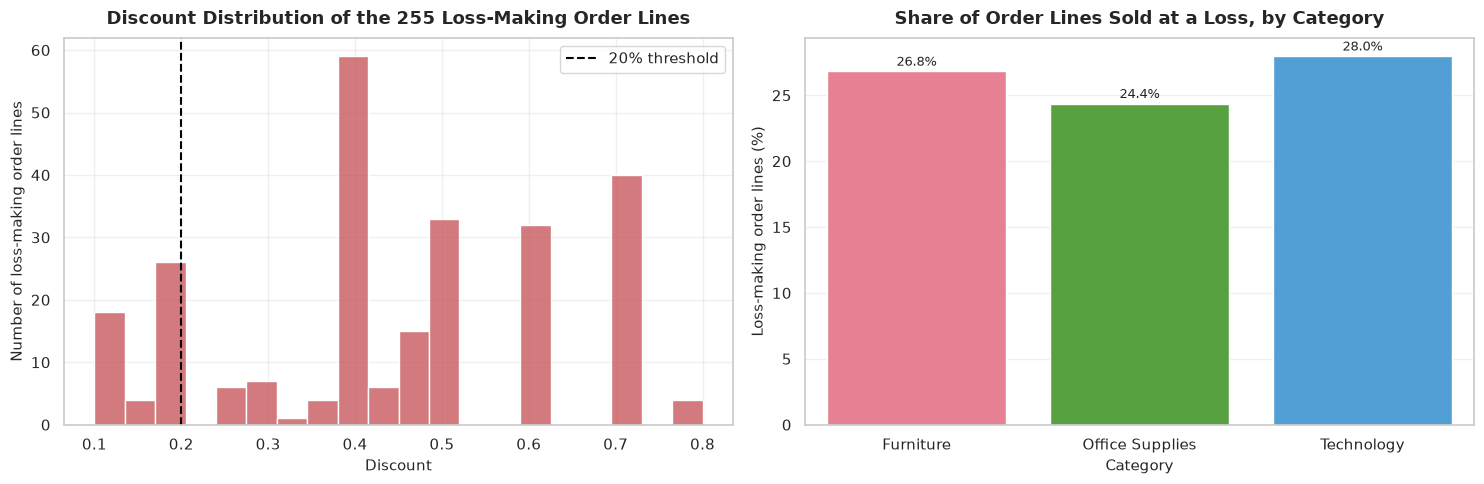

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(loss["Discount"], bins=20, color="#c44e52", ax=axes[0])
axes[0].axvline(0.20, color="black", linestyle="--", linewidth=1.5, label="20% threshold")
axes[0].set_title("Discount Distribution of the 255 Loss-Making Order Lines", pad=10)
axes[0].set_xlabel("Discount")
axes[0].set_ylabel("Number of loss-making order lines")
axes[0].legend(frameon=True)

comp = df.groupby("Category").apply(
    lambda g: pd.Series({
        "Loss-making %": (g["Profit"] < 0).mean() * 100,
        "Margin %": g["Profit"].sum() / g["Sales"].sum() * 100,
    }),
    include_groups=False,
).reset_index()

sns.barplot(data=comp, x="Category", y="Loss-making %", palette="husl", ax=axes[1])
axes[1].set_title("Share of Order Lines Sold at a Loss, by Category", pad=10)
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Loss-making order lines (%)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=2, fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "14_loss_making_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** 255 of 1,000 order lines (25.5%) lose money, and together they destroy
**-20,722.57** of profit against **+48,731.80** earned by the remaining 745 lines. In other
words the loss-making quarter of the portfolio consumes **43% of the profit the profitable
three quarters generate**.

**81.2% of these loss-making lines carry a discount above 20%**, against a 22.8% base rate for
all orders: loss-making lines are **3.6x over-represented** in the deep-discount band. By
category, `Technology` is the worst at 28.0% of its order lines sold at a loss, then `Furniture`
at 26.8% and `Office Supplies` at 24.4% - so the problem is portfolio-wide, not confined to one
category.

**Why it matters.** This closes the argument started in section 12. Deep discounting is not
merely correlated with losses - given that 81.2% of loss-making lines are discounted past 20%
against a 22.8% base rate, it is the dominant identifiable cause of them. The most valuable single
intervention available to this business is not increasing sales, it is **stopping discounting past
20%**.

## 13. Key Findings

In [41]:
key_figures = {
    "Order lines analysed": f"{len(df):,}",
    "Distinct orders": f"{df['Order ID'].nunique():,}",
    "Distinct customers": f"{df['Customer ID'].nunique():,}",
    "Distinct products": f"{df['Product Name'].nunique():,}",
    "Period": f"{df['Order Date'].min():%d %b %Y} to {df['Order Date'].max():%d %b %Y}",
    "Total revenue": f"{df['Sales'].sum():,.2f}",
    "Total profit": f"{df['Profit'].sum():,.2f}",
    "Overall margin": f"{df['Profit'].sum() / df['Sales'].sum() * 100:.2f}%",
    "Loss-making lines": f"{(df['Profit'] < 0).sum()} ({(df['Profit'] < 0).mean() * 100:.1f}%)",
    "Profit lost on loss-making lines": f"{df.loc[df['Profit'] < 0, 'Profit'].sum():,.2f}",
    "Orders per customer": f"{df['Order ID'].nunique() / df['Customer ID'].nunique():.2f}",
    "Repeat-customer rate": f"{(df.groupby('Customer ID')['Order ID'].nunique() > 1).mean() * 100:.1f}%",
    "Lines with discount > 20%": f"{(df['Discount'] > 0.20).sum()} ({(df['Discount'] > 0.20).mean() * 100:.1f}%)",
    "Profit from those lines": f"{df.loc[df['Discount'] > 0.20, 'Profit'].sum():,.2f}",
    "Strongest correlation (Sales~Ship. cost)": f"{df['Sales'].corr(df['Shipping Cost']):.3f}",
    "Strongest negative corr. (Disc.~Profit)": f"{df['Discount'].corr(df['Profit']):.3f}",
    "Rows / columns in the raw file": f"{df_raw.shape[0]:,} / {df_raw.shape[1]}",
    "Exact duplicate rows found": f"{df_raw.duplicated().sum()}",
}

for k, v in key_figures.items():
    print(f"{k:<42} : {v}")

pd.Series(key_figures).to_csv(OUTPUT_DIR / "key_figures.csv", header=["value"])

Order lines analysed                       : 1,000
Distinct orders                            : 979
Distinct customers                         : 654
Distinct products                          : 827
Period                                     : 01 Jan 2011 to 30 Dec 2014
Total revenue                              : 243,960.06
Total profit                               : 28,009.23
Overall margin                             : 11.48%
Loss-making lines                          : 255 (25.5%)
Profit lost on loss-making lines           : -20,722.57
Orders per customer                        : 1.50
Repeat-customer rate                       : 35.0%
Lines with discount > 20%                  : 228 (22.8%)
Profit from those lines                    : -19,036.19
Strongest correlation (Sales~Ship. cost)   : 0.878
Strongest negative corr. (Disc.~Profit)    : -0.332
Rows / columns in the raw file             : 1,000 / 24
Exact duplicate rows found                 : 0


## 14. Conclusions

In [42]:
conclusions = [
    "1.  DATA QUALITY IS GOOD, BUT THE NUMBERS ARE STORED AS TEXT.\n"
    "    All four money/percentage columns use the European decimal comma, so any analysis that\n"
    "    skips the conversion produces silently wrong results. After conversion the data is clean:\n"
    "    zero duplicate rows, zero unparsed dates, and only 'Postal Code' has missing values\n"
    "    (804 of 1,000), which is correct behaviour for international addresses.",

    "2.  TYPICAL ORDERS ARE FAR SMALLER THAN THE AVERAGE.\n"
    "    Mean sales per line is 243.96 but the median is 84.19 (skewness 4.69). Reporting averages\n"
    "    alone would overstate a typical order line by almost 3x.",

    "3.  2014 IS VOLUME GROWTH THAT HIDES A PROFITABILITY COLLAPSE - AND IT IS NOT A DISCOUNT\n"
    "    PROBLEM. Order lines grew 176 -> 326 and revenue peaked at 72,872, yet 2014's margin fell\n"
    "    from 16.14% to 8.01% and profit per order line dropped 57.2%. Crucially the mean discount\n"
    "    was FLAT (14.97% -> 15.03%) and shipping cost as a share of sales was flat\n"
    "    (11.58% -> 11.43%), so headline discounting does not explain it. The damage is\n"
    "    concentrated in big-ticket sub-categories whose margins inverted: Appliances 28.71% ->\n"
    "    -8.62%, Chairs 23.25% -> -5.69%, Copiers 20.63% -> -3.94%, while average unit price fell\n"
    "    from 78.92 to 66.09.",

    "4.  DISCOUNTING HAS A PROFITABILITY CLIFF AT 20%.\n"
    "    Margin is +25.37% at no discount and +10.18% at 11-20%, but turns negative from 21-30%\n"
    "    (-15.85%) and collapses to -59.58% beyond 30% - a 26 percentage point cliff between the\n"
    "    last profitable and the first unprofitable band. The 31%+ band is 20.9% of all lines yet\n"
    "    destroys 18,243, and the 21%+ bands together destroy 19,036 - 68% of the entire 28,009\n"
    "    company profit.",

    "5.  ONE QUARTER OF ALL ORDER LINES SELL AT A LOSS.\n"
    "    255 lines destroy -20,722.57 against +48,731.80 from all remaining lines, so the\n"
    "    loss-making quarter of the portfolio consumes 43% of what the profitable three quarters\n"
    "    generate. 81.2% of them carry a discount above 20% against a 22.8% base rate - a 3.6x\n"
    "    over-representation. The problem is portfolio-wide: 28.0% of Technology lines, 26.8% of\n"
    "    Furniture and 24.4% of Office Supplies sell at a loss.",

    "6.  TRANSACTION VOLUME AND VALUE SIT IN COMPLETELY DIFFERENT PLACES.\n"
    "    Office Supplies = 62.0% of order lines but only 18.9% of profit (6.90% margin).\n"
    "    Technology = 18.6% of lines but 42.6% of profit (14.72% margin) - more profit than the\n"
    "    other two categories combined. The best seller by units (Stockwell Paper Clips, 22 units,\n"
    "    194 of revenue) is 73x cheaper per unit than the top revenue line, while the 7th\n"
    "    best-selling product (Breville Microwave, 14 units) lost 1,736 on 2,117 of revenue - a\n"
    "    -82.0% margin.",

    "7.  BINDERS DESTROY 39% OF THE OFFICE SUPPLIES CATEGORY'S PROFIT.\n"
    "    -2,089 (-14.98% margin) on 13,946 of revenue, while Tables is break-even at -0.02%.\n"
    "    That is 39% of the 5,297 profit the whole Office Supplies category generates and 7.5%\n"
    "    of net company profit - a real single-category problem, but the deep-discount band is\n"
    "    roughly twice as large, so it ranks second in priority.",

    "8.  THE US MARKET IS REVENUE-HEAVY AND MARGIN-POOR, BUT IT IS IMPROVING.\n"
    "    The US is 16.7% of revenue (40,714) with only a 1.40% margin, against 10.52% in EMEA and\n"
    "    35.52% in Canada; market revenue and market margin are negatively related (r = -0.50).\n"
    "    Important caveat: the US margin runs -7.91% (2011), 9.09% (2012), 1.52% (2013), 20.03%\n"
    "    (2014), so this is a period-average problem concentrated in the earlier years, and 2014 is\n"
    "    the US's strongest year by a wide margin.",

    "9.  SHIPPING COST IS A PROPORTIONAL COST; SPEED BUYS NOTHING HERE.\n"
    "    Sales and Shipping Cost correlate at +0.88, so shipping must be modelled as a share of\n"
    "    order value. Delivery Days has essentially zero correlation with Sales (-0.01),\n"
    "    Profit (0.00) or Discount (-0.01), so premium delivery cannot be justified on these\n"
    "    figures. Unit Price (0.82 with Sales) drives order value far more than Quantity (0.31).",

    "10. SEGMENT PROFITABILITY IS THE OPPOSITE OF SEGMENT SIZE.\n"
    "    Consumer supplies 53.6% of order lines and 52.6% of revenue but has the WORST margin\n"
    "    (9.24%) and the lowest profit share (42.3%). Corporate has the best margin (14.46%) on\n"
    "    24.5% of revenue, and Home Office earns the most per customer (436.68 vs 374.04 and\n"
    "    326.60). Prioritising by order count would push effort towards the least profitable\n"
    "    segment.",

    "11. RETENTION IS THE LARGEST UNTOUCHED REVENUE POOL.\n"
    "    654 customers place 979 orders (1.50 orders per customer) and 65.0% (425 of 654) never\n"
    "    order again. A repeat customer generates 2.79x the total revenue of a one-time customer,\n"
    "    but only 1.12x per individual order - the gap is about frequency, not basket size.",

    "12. LIMITATION - NO DEMOGRAPHIC DATA EXISTS IN THIS DATASET.\n"
    "    There is no 'Age' and no 'Gender' field. Rather than fabricate them, customer analysis\n"
    "    used the attributes that genuinely exist (Segment, Market, Region, City, Country,\n"
    "    Ship Mode). Conclusions about age groups or gender cannot be drawn from this source.",
]

for line in conclusions:
    print(line + "\n")

1.  DATA QUALITY IS GOOD, BUT THE NUMBERS ARE STORED AS TEXT.
    All four money/percentage columns use the European decimal comma, so any analysis that
    skips the conversion produces silently wrong results. After conversion the data is clean:
    zero duplicate rows, zero unparsed dates, and only 'Postal Code' has missing values
    (804 of 1,000), which is correct behaviour for international addresses.

2.  TYPICAL ORDERS ARE FAR SMALLER THAN THE AVERAGE.
    Mean sales per line is 243.96 but the median is 84.19 (skewness 4.69). Reporting averages
    alone would overstate a typical order line by almost 3x.

3.  2014 IS VOLUME GROWTH THAT HIDES A PROFITABILITY COLLAPSE - AND IT IS NOT A DISCOUNT
    PROBLEM. Order lines grew 176 -> 326 and revenue peaked at 72,872, yet 2014's margin fell
    from 16.14% to 8.01% and profit per order line dropped 57.2%. Crucially the mean discount
    was FLAT (14.97% -> 15.03%) and shipping cost as a share of sales was flat
    (11.58% -> 11.43%),

## 15. Actionable Business Recommendations

Every recommendation below is tied to a number that was actually measured in this notebook.

### Recommendation 1 - Enforce a 20% discount ceiling and re-price the 31%+ band
**Evidence:** margin is +10.18% at 11-20% discount but -15.85% at 21-30% and **-59.58% at
31%+**. The 31%+ band represents 209 of 1,000 lines and destroys **18,243**, which is **65% of
the entire 28,009 company profit**. Taken together the 21%+ bands are only 228 lines but destroy
19,036, or **68%** of net profit.
**Action:** cap automatic discounts at 20%; route any deeper discount through a profitability
approval; re-cost the 209 deep-discounted lines so that every line clears a minimum margin floor.
**Expected impact:** recovering even half of the 18,243 loss roughly increases total profit by
~33%. This is the highest-value action in the analysis and it is the cheapest to implement.

### Recommendation 2 - Exit or restructure the Binders sub-category
**Evidence:** Binders lose **-2,089 (-14.98%)** on 13,946 of revenue and `Tables` is
break-even at -0.02%. Together they remove about 2,092 of profit - **39% of the 5,297 profit the
whole Office Supplies category generates**, and 10.1% of all profit lost across the portfolio.
**Action:** renegotiate supplier cost, raise unit price by ~15%, or phase out the loss-making
Binders/Tables SKUs and replace them with higher-margin accessories.
**Note on priority:** this is a genuine single-category problem, but at roughly half the value of
Recommendation 1, so it should be sequenced after the discount cap rather than instead of it.

### Recommendation 3 - Re-price US-market delivery economics
**Evidence:** the US is 16.7% of revenue (40,714) but delivers only **1.40% margin** (571),
while Africa earns 13.22%, EU 14.63% and Canada 35.52%. Shipping Cost correlates with Sales at
**+0.88**, so delivery is a proportional cost that the US appears not to be recovering.
**Action:** introduce a US-market delivery surcharge or free-shipping threshold above the order
median of 84.19, and review US fulfilment costs per shipment. Closing the gap between the US's
1.40% margin and EMEA's 10.52% is worth roughly 3,710 on current US revenue.
**Important caveat:** US margin is -7.91% (2011), 9.09% (2012), 1.52% (2013) and **20.03% (2014)**.
The US is already fixing itself, so this recommendation should target the *structural* delivery
cost problem rather than assume the recent margin is the run rate.

### Recommendation 4 - Shift commercial effort from Office Supplies to Technology and Corporate
**Evidence:** Office Supplies is 62.0% of order lines but only 18.9% of profit (6.90% margin);
Technology is 18.6% of lines but 42.6% of profit (14.72% margin). By segment, Corporate has the
best margin (14.46%) on only 24.5% of revenue, while Consumer - the largest segment at 53.6% of
lines - has the worst margin at 9.24%.
**Action:** target sales-effort, marketing budget and shelf-space toward Technology and Corporate
accounts, and toward the high-value products in the top-10 revenue table (Motorola Smart Phone,
GBC DocuBind, SAFCO Armchair). Stop treating transaction volume as a category or segment success
metric - it currently points almost exactly at the wrong places.

### Recommendation 5 - Run a retention programme on the 425 one-time customers
**Evidence:** 65.0% of customers (425 of 654) placed exactly one order; a repeat customer
generates **2.79x** the total revenue of a one-time customer (1.12x per individual order, so the
gain comes from frequency).
**Action:** trigger a post-purchase campaign (e.g. 60-90 days after delivery) offering a
low-value but **0-10% discounted** follow-up - deliberately inside the profitable discount band
(1-10% is the highest profit-per-line band at +73.39) - aimed at converting one-time buyers.
Applying that to the 425 dormant customers at even a 10% conversion rate is a meaningful revenue
addition that does not touch the unprofitable 21%+ band.

### Recommendation 6 - Model shipping as a percentage of order value and stop paying for speed
**Evidence:** Delivery Days correlates 0.00 with profit and -0.01 with sales, while shipping
cost scales with order value at +0.88. Unit Price (0.82 with Sales) drives order value far more
than Quantity (0.31).
**Action:** add a shipping-cost-to-revenue ratio to the pricing model and review whether
premium/express shipping options are worth their cost, since no revenue or profit benefit is
measurable in this data.

### Recommendation 7 - Protect the low-discount assortment
**Evidence:** the 0% discount band produces **+25.37% margin** on 56.4% of all lines, and the
1-10% band earns the highest profit per line of any band at **+73.39**.
**Action:** protect full-price availability on the top-10 revenue products and treat any move
into discounting on those specific SKUs as an exception requiring justification.

### Recommendation 8 - Review the big-ticket lines that inverted in 2014
**Evidence:** 2014's margin collapse came from sub-category inversions rather than deeper
discounting - `Appliances` 28.71% -> -8.62%, `Chairs` 23.25% -> -5.69%, `Copiers` 20.63% ->
-3.94% - while the mean discount stayed flat at ~15% and average unit price fell from 78.92 to
66.09.
**Action:** run a SKU-level margin review on Appliances, Chairs and Copiers covering landed cost,
carriage and returns, since the discount cap in Recommendation 1 will not fix a margin inversion
on a full-price order.

---

## 16. Limitations

* The file used is the **public 1,000-line sample** of the Global Superstore dataset, so absolute
  currency totals are sample-level, not full-business totals. The *patterns* are what matter here.
* No `Age` or `Gender` fields exist, so age-group and gender analysis is genuinely impossible
  from this source and has deliberately not been faked.
* The dataset does not state its currency unit, so figures are reported as "currency units".
* No customer-acquisition cost, marketing-spend or inventory data is present, so the profit
  impact of recommendations 1-8 cannot be converted into a guaranteed ROI.
* Correlation is not causation. The discount analysis shows a very strong association and a
  plausible mechanism, but a causal claim would require an experiment.
* The market revenue/margin relationship (r = -0.50) rests on only 7 markets, so treat it as a
  strong pattern rather than an estimated effect.
* Order lines are analysed individually; order-level margin would differ slightly.
* The 2014 sub-category margin inversions are based on 19-37 order lines each, so individual
  sub-category year-on-year margins are volatile and should be confirmed against the full dataset
  before being used to set pricing.

## 17. Outputs Generated by This Notebook

All files below are written to the `outputs/` folder of this project:

| File | Content |
|---|---|
| `01_missing_values_overview.png` | Missing-value map of all columns |
| `02_distributions_sales_profit_discount.png` | Sales / Profit / Discount distributions |
| `03_revenue_vs_profit_by_year.png` | Revenue vs. profit by year |
| `04_monthly_sales_trend.png` | Monthly revenue trend with 3-month moving average |
| `05_quarterly_revenue_and_margin.png` | Quarterly revenue and margin |
| `06_customer_segment_analysis.png` | Customer segment volume and margin |
| `07_market_revenue_profit.png` | Revenue, profit and margin by market |
| `08_top10_products_by_quantity.png` | Top 10 products by units sold |
| `09_top10_products_by_revenue.png` | Top 10 products by revenue |
| `10_revenue_and_margin_by_category.png` | Category revenue and margin |
| `11_subcategory_margin.png` | Profit margin by all 17 sub-categories |
| `12_correlation_heatmap.png` | Correlation heatmap of numeric variables |
| `13_discount_threshold_effect.png` | **The discount threshold effect** |
| `14_loss_making_analysis.png` | Loss-making order-line analysis |
| `yearly_summary.csv` | Yearly aggregates |
| `monthly_summary.csv` | Monthly aggregates |
| `quarterly_summary.csv` | Quarterly aggregates |
| `customer_segment_summary.csv` | Segment-level aggregates |
| `market_summary.csv` | Market-level aggregates |
| `category_summary.csv` | Category-level aggregates |
| `subcategory_margin.csv` | Sub-category margins |
| `discount_band_analysis.csv` | Discount band analysis |
| `top10_products_by_quantity.csv` | Top 10 by units |
| `top10_products_by_revenue.csv` | Top 10 by revenue |
| `key_figures.csv` | Headline numbers used in this report |

In [43]:
generated = sorted(p.name for p in OUTPUT_DIR.iterdir() if p.is_file())
print(f"{len(generated)} output files written to {PROJECT_NAME}/outputs:\n")
for name in generated:
    print(f"  {name:<48} {(OUTPUT_DIR / name).stat().st_size / 1024:8.1f} KB")

assert len(df) == len(df_raw), "Row count changed unexpectedly during cleaning"
print("\nFinal sanity checks passed.")
print(f"Notebook completed successfully - {len(df):,} order lines analysed.")

25 output files written to DataAnalytics-L1-EDARetailSales/outputs:

  01_missing_values_overview.png                       61.5 KB
  02_distributions_sales_profit_discount.png           99.7 KB
  03_revenue_vs_profit_by_year.png                     91.6 KB
  04_monthly_sales_trend.png                          212.1 KB
  05_quarterly_revenue_and_margin.png                 117.5 KB
  06_customer_segment_analysis.png                     62.2 KB
  07_market_revenue_profit.png                         95.4 KB
  08_top10_products_by_quantity.png                   140.5 KB
  09_top10_products_by_revenue.png                    151.2 KB
  10_revenue_and_margin_by_category.png                68.1 KB
  11_subcategory_margin.png                            88.8 KB
  12_correlation_heatmap.png                          125.7 KB
  13_discount_threshold_effect.png                    103.7 KB
  14_loss_making_analysis.png                          88.0 KB
  category_summary.csv                           